# Week 12: Outlier Detection

Outlier detection is the process of identifying observations that differ significantly from the dominant patterns in a dataset. Such observations may represent data errors, unusual but legitimate cases, or important events that deserve further investigation.

Detecting outliers is challenging because there is no single definition of what makes an observation unusual. A value may be extreme relative to one feature, inconsistent with relationships among several features, or located in a region where observations are uncommon. Moreover, an outlier detected by one method may be considered normal by another.

In this notebook, we will explore several approaches to outlier detection, beginning with univariate statistical methods and progressing to multivariate techniques, density-based methods, randomized trees, and neural networks. We will compare these approaches on synthetic datasets with known outliers, then use an autoencoder to detect unusual handwritten digits in MNIST.

## Learning Objectives

By the end of this notebook, you should be able to:

- Apply statistical methods such as Z-scores, median absolute deviation (MAD), and the interquartile range (IQR) to detect univariate outliers.
- Explain why relationships among features matter in multivariate outlier detection.
- Use Mahalanobis distance to identify observations that are unusual relative to a multivariate distribution.
- Apply DBSCAN, Local Outlier Factor, and Isolation Forest to detect anomalies.
- Build a simple neural network autoencoder and use reconstruction error to distinguish normal observations from potential anomalies.
- Evaluate outlier detectors using confusion matrices, precision, recall, and F1 when ground-truth labels are available.
- Compare the strengths and limitations of different approaches, and explain why detected outliers should not automatically be removed.

## Univariate Statistical Methods

For a dataset containing a single numerical feature, $X = \{x_1,\ldots,x_n\}$, an **outlier** is an observation that is unusually far from the bulk of the data.

Although this sounds straightforward, we must make two decisions:

- **How do we measure what is unusual?** We might use distance from the mean or median, or compare values with the spread of the middle portion of the data.
- **Where do we set the threshold?** Different thresholds, and different methods, may identify different observations as outliers.

We will examine four common statistical approaches, beginning with simple distance from the mean and progressing to methods that are more resistant to extreme values.

### Method 1: Absolute Deviation

The simplest approach, when the valid range of a feature is known, is to flag any values outside that range. But even when the range is not known precisely, we may have some idea of how far values should reasonably deviate from the mean.

We can use this knowledge to define an **absolute deviation** rule: A value $x_i$ is considered an outlier if

$$
|x_i-\mu| > T,
$$

where $\mu$ is the mean and $T$ is a threshold chosen based on our knowledge of the data.

> **Example: A Data Entry Error**
>
> Suppose someone entered the list $[5,1,3,2,4,6,7]$ by hand but accidentally omitted the final comma, producing
>
> $$[5,1,3,2,4,67].$$
>
> If these are supposed to be single-digit integers, the error is obvious: 67 falls outside the expected range of 0 to 9.
>
> But suppose we did not know the exact range, only that the values should ordinarily be within about 10 units of their mean. We could then choose $T=10$.
>
> For the corrupted dataset, the mean is $\mu=13.67$, so the deviation of 67 is
>
> $$
> |67-13.67|=53.33 > 10.
> $$
>
> Thus, 67 is flagged as an outlier.


The main limitation of absolute deviation is that **the threshold $T$ must be chosen in the original units of the data**. A distance of 10 might be enormous for one feature but insignificant for another. Moreover, extreme values can distort the mean itself.

We can address the first problem by measuring deviations relative to the **standard deviation**, which tells us how much the values typically vary around the mean.

### Method 2: Standard Z-Score

The **Z-score** measures how far an observation is from the mean in units of standard deviation:

$$
z_i = \frac{x_i-\mu}{\sigma},
$$

where $\mu$ is the mean and $\sigma$ is the standard deviation.

We flag an observation as an outlier when

$$
|z_i| > k.
$$

Typical choices are:

- $k=2$: approximately $4.55\%$ of observations fall outside this range.
- $k=3$: approximately $0.27\%$ of observations fall outside this range.

**These percentages assume a normal distribution.** For other distributions, the percentages may differ substantially.

The threshold $k$ determines how aggressively the method identifies outliers: smaller values flag more observations.

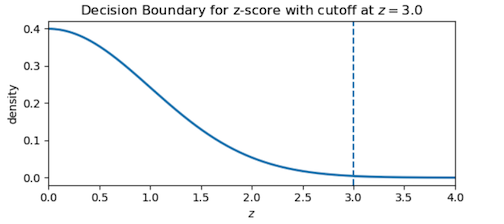

> **Example:**
>
> Let's return to our data-entry example, in which the list $[5,1,3,2,4,6,7]$ was accidentally entered as $[5,1,3,2,4,67]$. The value 67 is clearly suspicious, as we can see in the scatterplot:
>
> 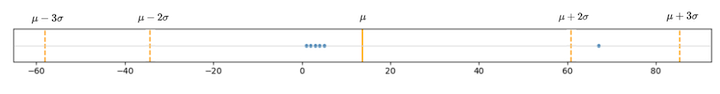
>
> For this dataset:
>
> - Mean: $\mu = 13.67$
> - Standard deviation: $\sigma = 23.87$
> - Outlier boundaries for $k=2$: $[-34.07,61.41]$
> - Outlier boundaries for $k=3$: $[-57.99,85.33]$
>
> Since $61.41 < 67 < 85.33$, the value 67 is flagged as an outlier with $k=2$, but **not with $k=3$**.
>
> This illustrates a weakness of the standard Z-score: the extreme value itself pulls the mean upward and increases the standard deviation, making it harder to identify as an outlier.

The underlying problem is that **both the mean and standard deviation are sensitive to extreme observations**. Our next method addresses this problem by replacing them with more robust measures of center and spread.

### Method 3: Robust Z-Score (Using MAD)

The problem with the standard Z-score is that both the mean and standard deviation are sensitive to extreme values. We can make the method more **robust** by replacing them with statistics that are less affected by outliers:

- The **median** instead of the mean.
- The **Median Absolute Deviation (MAD)** instead of the standard deviation.

Let $M$ be the median of the dataset. The MAD is the median of the absolute deviations from $M$:

$$
\operatorname{MAD} =
\operatorname{median}\left(|x_i-M| \text{ for } i=1,\ldots,n\right).
$$

We then define a **robust Z-score**:

$$
z_i^{\mathrm{MAD}} = \frac{x_i-M}{\operatorname{MAD}}.
$$

As before, we flag an observation as an outlier when

$$
|z_i^{\mathrm{MAD}}| > k.
$$

The key difference is that neither the center nor the measure of spread is strongly influenced by a few extreme observations.

> **Example:**
>
> Returning to our corrupted dataset $[5,1,3,2,4,67]$:
>
> **Median:**
>
> $$M = \operatorname{median}([5,1,3,2,4,67])= \operatorname{median}([1,2,3,4,5,67]) = 3.5.$$
>
> **Absolute deviations from the median:**
>
> $$|x_i-M| = [1.5,2.5,0.5,1.5,0.5,63.5].$$
>
> **Median Absolute Deviation:**
>
> $$\operatorname{MAD} = 1.5.$$
>
> **Robust Z-scores:**
>
> $$[1.0,-1.67,-0.33,-1.0,0.33,random_seed.33].$$
>
> For $k=3$, the value 67 is clearly identified as an extreme outlier because $random_seed.33 > 3$.
>
> Notice that the median remains at 3.5 despite the extreme value of 67, whereas the mean was pulled upward to 13.67.

**Notes:**

- The median and MAD are **robust statistics**: their values are much less affected by a few extreme observations than the mean and standard deviation.
- Ideally, we would calculate the center and spread of the data *without the outliers*, but we do not yet know which observations are outliers. Robust statistics help us address this circular problem.
- Unlike the standard Z-score, this MAD-based score does not measure distance in units of standard deviation. Consequently, the same threshold $k$ does not necessarily produce comparable results. In particular, the normal-distribution percentages given for standard Z-scores do not apply directly.

### Method 4: Boxplot (Using the IQR Rule)

Another robust approach uses **quartiles** and the **interquartile range (IQR)**. This method is the basis of the **boxplot**, a visualization developed by statistician John Tukey.

The three quartiles divide the sorted data into four approximately equal parts:

- $Q_1$: the 25th percentile
- $Q_2$: the 50th percentile (the median)
- $Q_3$: the 75th percentile

The **interquartile range (IQR)** measures the spread of the middle 50% of the data:

$$
\mathrm{IQR} = Q_3-Q_1.
$$

The standard **IQR outlier rule** flags an observation $x_i$ as an outlier if

$$
x_i < Q_1-1.5\cdot\mathrm{IQR}
\quad\text{or}\quad
x_i > Q_3+1.5\cdot\mathrm{IQR}.
$$

The two thresholds define the **outlier boundaries**, often called *fences*. In a standard boxplot, the box extends from $Q_1$ to $Q_3$, with a line at the median. The whiskers extend to the most extreme observed values within the fences, and observations beyond them are plotted individually as outliers.

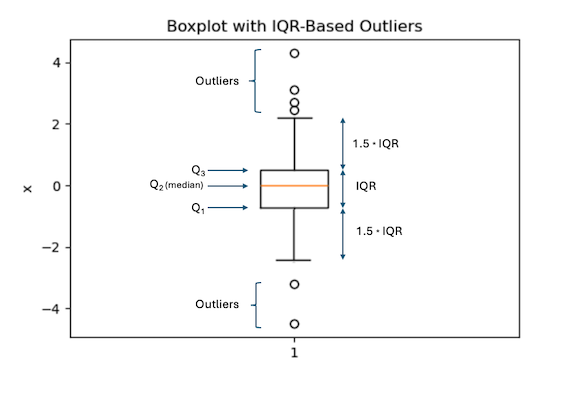

> **Example:**
>
> Returning once again to our corrupted dataset $[5,1,3,2,4,67]$, we first calculate the quartiles:
>
> $$Q_1=2.25,\qquad Q_2=3.5,\qquad Q_3=4.75.$$
>
> The interquartile range is
>
> $$\mathrm{IQR}=4.75-2.25=2.5.$$
>
> The outlier boundaries are:
>
> - Lower: $Q_1-1.5(\mathrm{IQR})=2.25-1.5(2.5)=-1.5$
> - Upper: $Q_3+1.5(\mathrm{IQR})=4.75+1.5(2.5)=8.5$
>
> Since $67>8.5$, the value 67 is identified as an outlier, as shown in the boxplot:
>
> 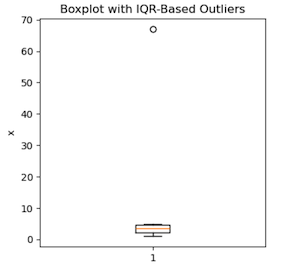

**Notes:**

- The factor **1.5** is a conventional choice introduced by Tukey. It determines how far observations may lie beyond the middle 50% before being flagged.
- The IQR rule is **nonparametric**: it does not assume a normal distribution.
- Like the median and MAD, quartiles and the IQR are **robust statistics**, relatively insensitive to extreme observations.
- Most plotting libraries use this rule by default when displaying outliers in boxplots.

### Limitations of Univariate Methods

All these methods examine observations along a single numerical dimension. They differ in how they measure distance and variability, but they share an important limitation: **they cannot detect unusual relationships between features**.

For example, a person's height and weight might each be within a normal range, while the particular combination of height and weight is highly unusual.

To recognize such observations, we must consider multiple features simultaneously. This leads us to **multivariate outlier detection**.

### Python Examples for Univariate Outlier Detection

#### Create a one-dimensional normally-distributed dataset with outliers

In [1]:
# Useful imports

# General utilities and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Statistical methods
from scipy.stats import chi2

# Scikit-learn: Datasets and preprocessing
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split

# Scikit-learn: Outlier detection
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

# Scikit-learn: Evaluation
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# TensorFlow / Keras
from tensorflow import keras
from tensorflow.keras import layers, models

# Reproducibility
random_seed = 42

Mean (μ): -0.108, Std dev (σ): 1.204


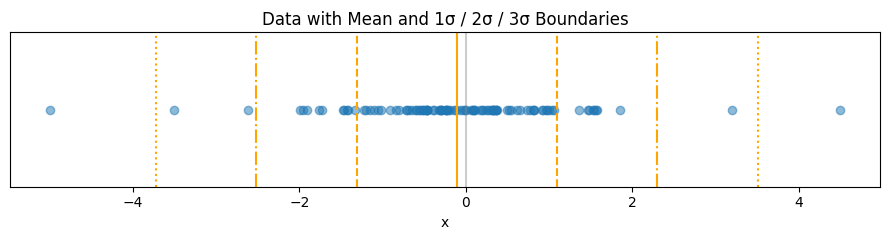

In [2]:
# Create a 1D dataset with normally distributed observations and four outliers

np.random.seed(random_seed)

x_inliers = np.random.normal(loc=0.0, scale=1.0, size=100)
x_outliers = np.array([-5.0, -3.5, 3.2, 4.5])
x = np.concatenate([x_inliers, x_outliers])

# Compute mean and standard deviation
mu = x.mean()
sigma = x.std(ddof=1)

print(f"Mean (μ): {mu:.3f}, Std dev (σ): {sigma:.3f}")

# Plot observations and standard deviation boundaries
fig, ax = plt.subplots(figsize=(9, 2.5))

ax.scatter(x, np.zeros_like(x), alpha=0.5)

# Mean
ax.axvline(mu, color="orange")

# Boundaries at ±1σ, ±2σ, and ±3σ
for k, style in zip([1, 2, 3], ["--", "-.", ":"]):
    ax.axvline(mu - k * sigma, color="orange", linestyle=style)
    ax.axvline(mu + k * sigma, color="orange", linestyle=style)

ax.axvline(0, color="grey", alpha=0.4)

ax.set_yticks([])
ax.set_xlabel("x")
ax.set_title("Data with Mean and 1σ / 2σ / 3σ Boundaries")

plt.tight_layout()
plt.show()

### Method 2: Standard Z-Score

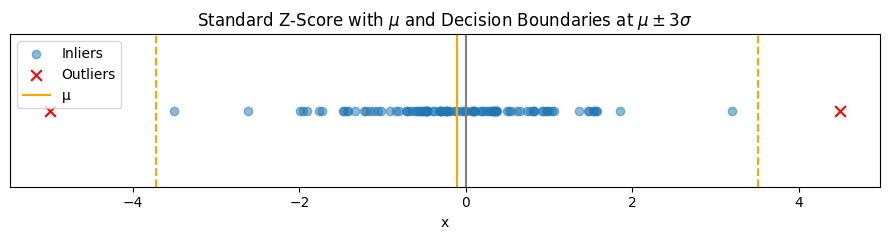

Mean:                -0.1075
Standard Deviation:  1.2038
Decision boundaries: [-3.719   3.5039]
Z-score outliers:    [-5.   4.5]
Number of outliers:  2 / 104 (1.92% of the data)


In [3]:
mu = x.mean()
sigma = x.std(ddof=1)

z = (x - mu) / sigma
k = 3  # 3-sigma rule
mask_z = np.abs(z) > k


# x : your data (1D array)
# mu, sigma : mean and std of x
# k : z-score cutoff (e.g., 3)
# mask_z : boolean mask for |z| > k

bounds_z = [mu - k * sigma, mu + k * sigma]

fig, ax = plt.subplots(figsize=(9, 2.5))

# 1D scatter: non-outliers and outliers
ax.scatter(x[~mask_z], np.zeros(np.sum(~mask_z)),
           alpha=0.5, label="Inliers")
ax.scatter(x[mask_z], np.zeros(np.sum(mask_z)),
           color="red", marker="x", s=60, label="Outliers")

# Vertical lines at μ ± kσ
for b in bounds_z:
    ax.axvline(b, color="orange", linestyle="--")

# zero-line
ax.axvline(0, color="grey")

# vertical line at mean
ax.axvline(mu, color="orange", label="μ")

ax.set_yticks([])
ax.set_xlabel("x")
ax.set_title(f"Standard Z-Score with $\mu$ and Decision Boundaries at $\mu\pm 3\sigma$")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# ---- Print summary ----
num_outliers = np.sum(mask_z)
total_points = len(x)
percent_outliers = 100 * num_outliers / total_points

print(f"Mean:                {np.around(mu,4)}")
print(f"Standard Deviation:  {np.around(sigma,4)}")
print(f"Decision boundaries: {np.around(bounds_z, 4)}")
print(f"Z-score outliers:    {x[mask_z]}")
print(f"Number of outliers:  {num_outliers} / {total_points} "
      f"({percent_outliers:.2f}% of the data)")



### Method 3: Robust Z-Score

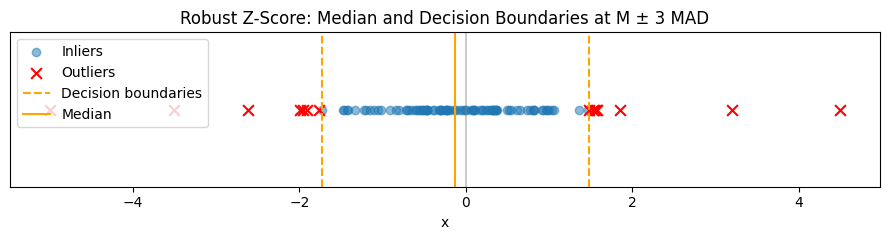

Median:                    -0.1270
MAD:                       0.5341
Robust bounds (M ± k·MAD): [-1.7292, 1.4752]
Robust Z-score outliers:   [ 1.523   1.5792 -1.9133  1.8523 -1.9597 -1.763   1.538   1.5646 -2.6197
 -1.9876  1.4779 -5.     -3.5     3.2     4.5   ]
Number of outliers:        15 / 104 (14.42% of the data)


In [4]:
# Robust Z-score using the median and Median Absolute Deviation (MAD)

M = np.median(x)
MAD = np.median(np.abs(x - M))

k = 3  # Threshold for MAD-based score (not a 3-sigma rule)

z_robust = (x - M) / MAD
mask_robust = np.abs(z_robust) > k

# Decision boundaries
lower_bound = M - k * MAD
upper_bound = M + k * MAD

# Plot results
fig, ax = plt.subplots(figsize=(9, 2.5))

ax.scatter(
    x[~mask_robust], np.zeros_like(x[~mask_robust]),
    alpha=0.5, label="Inliers"
)
ax.scatter(
    x[mask_robust], np.zeros_like(x[mask_robust]),
    color="red", marker="x", s=60, label="Outliers"
)

ax.axvline(lower_bound, color="orange", linestyle="--",
           label="Decision boundaries")
ax.axvline(upper_bound, color="orange", linestyle="--")
ax.axvline(M, color="orange", label="Median")
ax.axvline(0, color="grey", alpha=0.4)

ax.set_yticks([])
ax.set_xlabel("x")
ax.set_title(f"Robust Z-Score: Median and Decision Boundaries at M ± {k} MAD")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Print summary
num_outliers = mask_robust.sum()
total_points = len(x)
percent_outliers = 100 * num_outliers / total_points

print(f"Median:                    {M:.4f}")
print(f"MAD:                       {MAD:.4f}")
print(f"Robust bounds (M ± k·MAD): [{lower_bound:.4f}, {upper_bound:.4f}]")
print(f"Robust Z-score outliers:   {np.round(x[mask_robust], 4)}")
print(f"Number of outliers:        {num_outliers} / {total_points} "
      f"({percent_outliers:.2f}% of the data)")

### Method 4: BoxPlots

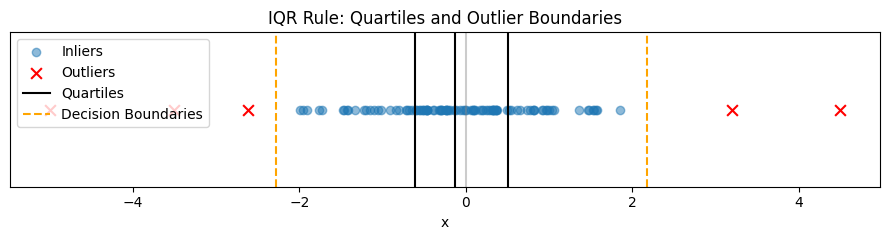

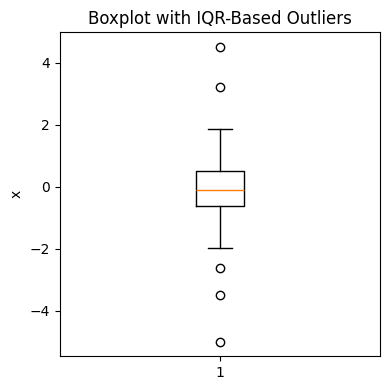

Q1 = -0.6126, Median (Q2) = -0.1270, Q3 = 0.5009
IQR =               1.1134
1.5*IQR bounds:     [-2.2827, 2.1710]
IQR-rule outliers:  [-5.0, -3.5, -2.6197, 3.2, 4.5]
Number of outliers: 5 / 104 (4.81% of the data)


In [5]:
# IQR-based outlier detection

Q1, Q2, Q3 = np.percentile(x, [25, 50, 75])
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask_iqr = (x < lower_bound) | (x > upper_bound)

# Plot observations with quartiles and outlier boundaries
fig, ax = plt.subplots(figsize=(9, 2.5))

ax.scatter(
    x[~mask_iqr], np.zeros((~mask_iqr).sum()),
    alpha=0.5, label="Inliers"
)
ax.scatter(
    x[mask_iqr], np.zeros(mask_iqr.sum()),
    color="red", marker="x", s=60, label="Outliers"
)

# Quartiles
ax.axvline(Q1, color="black", label="Quartiles")
ax.axvline(Q2, color="black")
ax.axvline(Q3, color="black")

# IQR fences
ax.axvline(lower_bound, color="orange", linestyle="--",
           label="Decision Boundaries")
ax.axvline(upper_bound, color="orange", linestyle="--")

ax.axvline(0, color="grey", alpha=0.4)

ax.set_yticks([])
ax.set_xlabel("x")
ax.set_title("IQR Rule: Quartiles and Outlier Boundaries")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Boxplot using the same IQR rule
plt.figure(figsize=(4, 4))
plt.boxplot(x, showfliers=True)
plt.title("Boxplot with IQR-Based Outliers")
plt.ylabel("x")
plt.tight_layout()
plt.show()

# Print summary
num_outliers = mask_iqr.sum()
total_points = len(x)
percent_outliers = 100 * num_outliers / total_points

print(f"Q1 = {Q1:.4f}, Median (Q2) = {Q2:.4f}, Q3 = {Q3:.4f}")
print(f"IQR =               {IQR:.4f}")
print(f"1.5*IQR bounds:     [{lower_bound:.4f}, {upper_bound:.4f}]")
print(f"IQR-rule outliers:  {sorted(np.round(x[mask_iqr], 4))}")
print(f"Number of outliers: {num_outliers} / {total_points} "
      f"({percent_outliers:.2f}% of the data)")

## The Multivariate (Vector) Case

### From Univariate to Multivariate Outlier Detection

So far, we have considered datasets containing a single numerical feature. But most machine learning datasets contain many features, and an observation may be unusual because of its **combination of feature values**, even when none of the individual values is unusual.

Consider a dataset with $n$ samples and $p$ features, represented by the matrix

$$
X =
\begin{pmatrix}
x_{1}^{(1)} & x_{1}^{(2)} & \cdots & x_{1}^{(p)} \\
x_{2}^{(1)} & x_{2}^{(2)} & \cdots & x_{2}^{(p)} \\
\vdots      & \vdots      & \ddots & \vdots      \\
x_{n}^{(1)} & x_{n}^{(2)} & \cdots & x_{n}^{(p)}
\end{pmatrix}.
$$

Each row represents a sample, and each column represents a feature. Since each column is itself a univariate dataset, we can apply any of our previous outlier detection methods to the features individually.

### Coordinatewise (Marginal) Outlier Detection

The simplest approach to detecting outliers in a multivariate dataset is to **apply a univariate method separately to each feature**.

For each feature $j=1,\ldots,p$, consider its values

$$
x_1^{(j)},x_2^{(j)},\ldots,x_n^{(j)}.
$$

Apply a univariate outlier rule, such as a Z-score or the IQR rule, to this column. Then flag an entire sample $x_i$ as an outlier if **any of its feature values** is flagged.

This is called **coordinatewise** or **marginal** outlier detection because we examine each feature's *marginal distribution*—its distribution considered independently of the other features.

**Advantages:**

- Simple to understand and implement using methods we already know.
- Particularly useful for detecting data-entry errors or faulty sensor readings that produce extreme values in individual features.

**Limitations:**

The fundamental limitation is that coordinatewise methods **ignore relationships and correlations among features**.

For example, consider a dataset containing people's heights and weights. A height of 6 feet may be perfectly ordinary, and a weight of 120 pounds may also be within the observed range. However, the combination of these values may be highly unusual for the population being studied.

A coordinatewise method might miss this observation because neither feature is individually extreme. To identify such cases, we need methods that consider **multiple features simultaneously**.

There is also a practical concern: as the number of features increases, the chance that at least one feature exceeds its threshold also increases. Consequently, the rule of flagging a sample when *any* feature is unusual may identify too many outliers in high-dimensional datasets.

This motivates our next approach, **Mahalanobis distance**, which measures how unusual an observation is while accounting for the correlations among its features.

### Multivariate Outlier Detection: Mahalanobis Distance

Coordinatewise methods examine each feature separately, ignoring relationships among features. To detect observations that are unusual because of their **combination of feature values**, we need a method that considers each sample as a complete vector.

**Mahalanobis distance** provides such a method. It generalizes the idea of a Z-score to multiple dimensions by accounting for differences in feature variability and correlations among features.

#### The Covariance Matrix

To understand Mahalanobis distance, we first need the **covariance matrix**, which describes how features vary individually and together.

$$
\Sigma = \operatorname{Cov}(X).
$$

Each entry is the covariance between two features:

$$
\Sigma_{j,k}
= \operatorname{Cov}(x^{(j)},x^{(k)})
= \mathbb{E}\left[(x^{(j)}-\mu_j)(x^{(k)}-\mu_k)\right].
$$

Here, $\mu_j$ and $\mu_k$ are the means of features $j$ and $k$.

**Properties of the covariance matrix:**

- $\Sigma$ is symmetric.
- The diagonal entries $\Sigma_{j,j}$ are the variances of the individual features.
- The off-diagonal entries describe how pairs of features vary together.
- Together, these values describe the spread, shape, and orientation of the data.

The correlation matrix, which we have used in heatmaps, is obtained by dividing each covariance by the standard deviations of the corresponding features.

**Example:**

The figure below illustrates two bivariate distributions. On the left, the features are independent and have equal variances, producing an approximately circular cloud of points. On the right, the features are strongly correlated (approximately 0.83), producing an elongated, elliptical cloud.

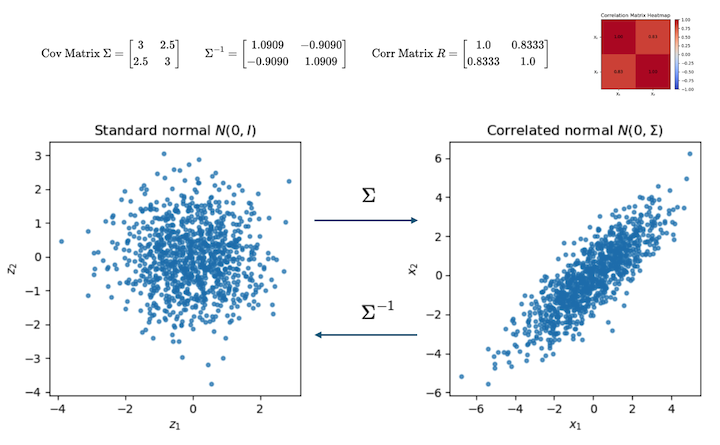

This distinction matters for outlier detection. A point may be far from the center in ordinary Euclidean distance but perfectly consistent with the elongated shape of the data. Another point may be closer to the center but lie in a direction where observations rarely occur.

**Mahalanobis distance takes this shape into account.**

#### Mahalanobis Distance

Instead of measuring ordinary Euclidean distance from the mean, we measure distance relative to the variability and correlations captured by the covariance matrix.

The **Mahalanobis distance** of an observation $x$ from the mean vector $\mu$ is

$$
D_M(x)
=
\sqrt{
(x-\mu)^\top\Sigma^{-1}(x-\mu)
}.
$$

Here:

- $x$ is the vector of feature values for one observation.
- $\mu$ is the vector of feature means.
- $\Sigma^{-1}$ is the inverse of the covariance matrix, assumed to exist.

The effect of the covariance matrix can be understood geometrically:

- If $\Sigma=I$, Mahalanobis distance reduces to ordinary Euclidean distance.
- If features have different variances, the distance adjusts for their different scales.
- If features are correlated, it accounts for those correlations when measuring distance.

Thus, rather than treating all directions in feature space equally, Mahalanobis distance measures how unusual a point is relative to the **shape of the data distribution**.

Points at equal Mahalanobis distance lie on ellipses in two dimensions (and ellipsoids in higher dimensions), rather than circles.

#### Decision Rule: Identifying Outliers

To decide which observations to flag, we need a threshold.

If the data follow a **multivariate normal distribution**, the squared Mahalanobis distance follows a chi-square ($\chi^2$) distribution with $p$ degrees of freedom, assuming the population mean and covariance are known.

This gives us a statistical basis for choosing a threshold.

1. Compute the **squared Mahalanobis distance**, $D_M(x)^2$, for each observation.
2. Choose a cutoff percentile, such as 0.975 or 0.99.
3. Find the corresponding chi-square cutoff for $p$ features.
4. Flag observations whose squared distance exceeds the cutoff.

For example, using the 99th percentile, the decision rule is

$$
D_M(x)^2 > \chi^2_{p,\,0.99}.
$$

Under the multivariate normal model, this boundary contains approximately 99% of the distribution, leaving the most extreme 1% outside.

A lower cutoff percentile flags more observations, while a higher percentile is more conservative.

**Important:** These probabilities assume multivariate normality and known population parameters. In practice, we estimate the mean and covariance from data, so the chi-square thresholds are approximate. Extreme observations can also distort these estimates.

#### Interpretation

Mahalanobis distance is the **multivariate analogue of the absolute Z-score**: it measures distance from the mean while accounting for the variability and correlations among features.

It is particularly useful when the data form a roughly elliptical distribution. However, it may be less effective for data containing multiple clusters, nonlinear patterns, or strongly non-normal distributions.

These limitations motivate the density-based, tree-based, and neural network approaches we will examine later.


### Method 3: DBSCAN

We studied **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** in Week 8 as an unsupervised clustering algorithm. Recall that DBSCAN identifies clusters of arbitrary shapes using two hyperparameters:

- **`eps`:** The neighborhood radius.
- **`min_samples`:** The minimum number of observations within that neighborhood (including the point itself) required to form a core point.

DBSCAN identifies core points, border points, and **noise points**. In scikit-learn, noise points are assigned the label `-1`.

**Here, we use DBSCAN for outlier detection rather than clustering:** observations labeled as noise are treated as potential outliers.

We will apply DBSCAN to our four datasets, first using the same hyperparameters for all four, then adjusting `eps` separately for each dataset.

As you may recall, **the choice of `eps` is critical**: too small a radius can classify many normal observations as noise, while too large a radius may cause genuine outliers to be absorbed into clusters.


### Method 4: Local Outlier Factor (LOF)

**Local Outlier Factor (LOF)** is an outlier detection algorithm that identifies observations whose surrounding region is unusually sparse **compared with the neighborhoods of nearby observations**.

The key idea is that an observation need not be far from the overall dataset to be an outlier. It may simply be isolated relative to its immediate neighbors.

#### Why Local Density Matters

Consider a dataset containing two clusters:

- One cluster is tightly packed, with observations very close together.
- The other cluster is more spread out, with greater distances between observations.

A method using a single global distance or density threshold might incorrectly flag many observations in the second cluster as outliers.

LOF addresses this problem by evaluating each observation **relative to the density of its own neighborhood**, rather than using the same standard everywhere.

#### How LOF Works

For each observation $x$, LOF:

1. Finds its $k$ nearest neighbors.
2. Estimates the local density around $x$ using distances to these neighbors.
3. Estimates the local densities of the neighbors themselves.
4. Compares the neighbors' densities with the density around $x$.

The resulting **Local Outlier Factor** is approximately the ratio of the neighbors' average local density to the observation's own local density.

We can interpret this score as follows:

- **LOF ≈ 1:** The observation has a density similar to its neighbors and is likely an inlier.
- **LOF > 1:** The observation is in a less dense region than its neighbors and is a potential outlier.
- **LOF < 1:** The observation is in a denser region than its neighbors.

Larger LOF scores indicate stronger evidence of local unusualness.

#### LOF vs. DBSCAN

Both methods use neighborhoods and density, but they approach outlier detection differently.

- **DBSCAN** identifies dense clusters and labels observations outside those clusters as noise.
- **LOF** assigns each observation an anomaly score based on how its local density compares with that of its neighbors.

Thus, LOF can identify observations that are unusual **within or near a cluster**, even when they are not isolated from the dataset as a whole.

#### Important Hyperparameters

In scikit-learn, we will use `LocalOutlierFactor` with two important parameters:

- **`n_neighbors`:** The number of neighbors used to estimate local density. Small values emphasize very local patterns; larger values consider a broader neighborhood.
- **`contamination`:** The assumed proportion of outliers, used to determine the threshold for converting anomaly scores into binary predictions.

For example:

```python
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
labels = lof.fit_predict(X)
y_pred = labels == -1
```

As with DBSCAN, `fit_predict()` returns **+1 for inliers** and **−1 for outliers**.

We can also inspect the anomaly scores using `negative_outlier_factor_`. These are the negatives of the LOF scores, so **more negative values indicate more anomalous observations**.

We will apply LOF to all four synthetic datasets and examine whether comparing local densities is more effective than the methods we have studied so far.

### Method 5: Isolation Forest

**Isolation Forest** takes a different approach to outlier detection. Rather than measuring distances or densities, it uses an ensemble of randomly constructed decision trees to identify unusual observations.

The key idea is that **outliers are often easier to isolate than normal observations**.

Each tree is constructed by repeatedly:

1. Randomly selecting a feature.
2. Randomly selecting a split value within the observed range of that feature.
3. Dividing the observations into two groups.
4. Continuing until observations are isolated or a stopping condition is reached.

An observation far from the bulk of the data can often be isolated in just a few splits. Observations in dense regions typically require more splits.

Isolation Forest builds many such trees and measures the **average path length** required to isolate each observation.

- **Short average path length:** More likely to be an outlier.
- **Long average path length:** More likely to be a normal observation.

This connects to the decision trees and ensemble methods we studied earlier. However, unlike a Random Forest, Isolation Forest does not learn to predict target labels. Its trees use random splits rather than selecting splits to minimize impurity.

The main hyperparameters include:

- `n_estimators`: Number of isolation trees in the ensemble.
- `max_samples`: Number of observations used to construct each tree.
- `contamination`: Expected proportion of outliers, used to set the classification threshold.

Because Isolation Forest does not assume a particular probability distribution or cluster shape, it can be applied to a wide variety of datasets. However, its effectiveness still depends on the structure of the data.

## Multivariate Outlier Detection: Python Examples

We will now compare several outlier detection methods using **four synthetic datasets**, each with a different structure. Our goal is to understand how the shape and distribution of the data affect the performance of different methods.

Each dataset contains **300 normal observations and 6 deliberately introduced outliers**. Because we know which observations are outliers, we can evaluate each method using confusion matrices, precision, recall, and F1.

We will use the following datasets:

1. **Correlated Gaussian:** A single elongated cloud of points with strongly correlated features. This dataset is particularly useful for demonstrating Mahalanobis distance.
2. **Three Clusters:** Three distinct groups of observations. This challenges methods that assume the data form a single distribution.
3. **Anisotropic Blobs:** Three clusters with elongated, directional shapes. This tests whether methods can handle clusters with different geometric structures.
4. **Two Moons:** Two curved, nonlinear clusters. This provides a particularly interesting challenge for methods based on global distances or simple distributional assumptions.

We will apply the same five outlier detection methods to all four datasets: coordinatewise Z-scores, Mahalanobis distance, DBSCAN, Local Outlier Factor (LOF), and Isolation Forest.

For each method, we will visualize the results using four categories:

- **True Positive (TP):** An outlier correctly detected.
- **False Positive (FP):** A normal observation incorrectly flagged as an outlier.
- **False Negative (FN):** An outlier the method failed to detect.
- **True Negative (TN):** A normal observation correctly identified.

By comparing the results across different distributions, we can explore a central question:

**Is there a single best method for detecting outliers, or does the appropriate method depend on the structure of the data?**

### Constructing Four Synthetic Datasets with Outliers

In [6]:
# -----------------------------
# 1. Just a Gaussian smear with 6 outliers
# -----------------------------
rng = np.random.default_rng(0)

# Correlated inliers (bivariate normal)
n_inliers = 300
mean = np.array([0.0, 0.0])
cov  = np.array([[3.0, 2.5],
                 [2.5, 3.0]])   # strong positive correlation

X_in1 = rng.multivariate_normal(mean, cov, size=n_inliers)      

# A few obvious outliers
X_out1 = np.array([
    [ 2.0,  6.0],
    [-6.0,  5.0],
    [ 6.0, 2.0],
    [ 5.0, -3.0],
    [-5.0, -4.0],
    [ 4.0,  8.0],
])

y_true1 = np.array(
    [False] * len(X_in1) + [True] * len(X_out1)
)

# Combine
X1 = np.vstack([X_in1, X_out1])     # shape (n, 2)



In [7]:


X_in2, y = make_blobs(
    n_samples=300,
    n_features=2,
    centers=3,
    cluster_std=1.8,
    center_box=(-10.0, 10.0),
    shuffle=True,
    random_state=random_seed,
    return_centers=False
)

# A few obvious outliers
X_out2 = np.array([
    [-10.0,  6.0],
    [-6.0,  4.0],
    [-10.0,  0.0],
    [ 7.0, -5.0],
    [ 2.5, -9.0],
    [ 4.0,  13.0],
])

y_true2 = np.array(
    [False] * len(X_in2) + [True] * len(X_out2)
)

X2 = np.vstack([X_in2, X_out2])


In [8]:
# 1. Start with isotropic Gaussian blobs
X_in, y_true = make_blobs(
    n_samples=300,
    n_features=2,
    centers=3,
    cluster_std=2.0,
    random_state=random_seed,
)

# 2. Apply a linear transformation to make them anisotropic
transformation = np.array([[0.6, 0.1],
                           [0.4,  0.85]])   

X_aniso = X_in @ transformation  

# A few obvious outliers
X_out3 = np.array([
    [-5.0,  2.0],
    [-2.5,  5.0],
    [-10.0,  0.0],
    [ 7.0, -5.0],
    [ 2.5, -9.0],
    [ 8.0,  13.0],
])

y_true3 = np.array(
    [False] * len(X_aniso) + [True] * len(X_out3)
)


X3 = np.vstack([X_aniso, X_out3])


In [9]:
# -----------------------------
# Dataset 4: Two Moons
# -----------------------------

X_in4, _ = make_moons(
    n_samples=300,
    noise=0.06,
    random_state=random_seed
)

# Deliberately introduced outliers
X_out4 = np.array([
    [ 0.5,  0.25],   # Between the moons
    [ -0.5,  0.10],   # Between the moons
    [-1.5,  1.0],    # Far left
    [ 2.5,  1.2],    # Far right
    [ 0.5,  1.7],    # Above
    [ 1.0, -1.2],    # Below
])

X4 = np.vstack([X_in4, X_out4])

y_true4 = np.array(
    [False] * len(X_in4) + [True] * len(X_out4)
)



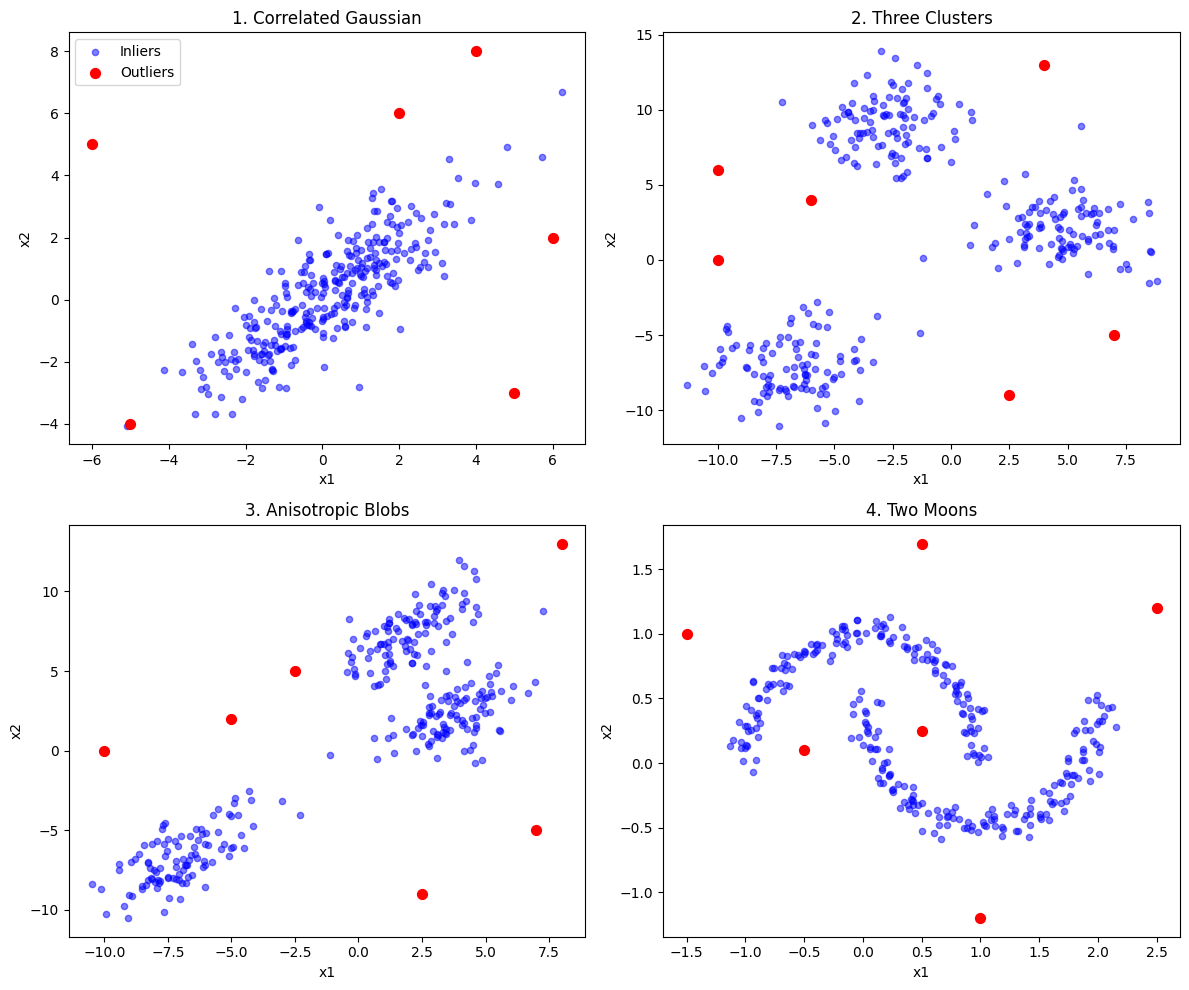

In [10]:
datasets = [
    (X1, y_true1, "1. Correlated Gaussian"),
    (X2, y_true2, "2. Three Clusters"),
    (X3, y_true3, "3. Anisotropic Blobs"),
    (X4, y_true4, "4. Two Moons"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (X, y_true, title) in zip(axes.flat, datasets):
    ax.scatter(X[~y_true, 0], X[~y_true, 1],
               s=20, alpha=0.5, color="blue", label="Inliers")
    ax.scatter(X[y_true, 0], X[y_true, 1],
               s=50, color="red", label="Outliers")

    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

In [11]:
COLORS = {
    "TN": "#4c6ef5",   # blue
    "FP": "#f59f00",   # orange
    "FN": "#e03131",   # red
    "TP": "#2f9e44",   # green
}

def plot_outlier_results(ax_scatter, ax_cm, ax_metrics, X, y_true, y_pred, title=""):
    """
    Plot one dataset with:
      - scatterplot on the left
      - compact confusion matrix on the upper-right
      - metrics text on the lower-right
    """

    # Boolean masks
    tn_mask = (~y_true) & (~y_pred)
    fp_mask = (~y_true) & ( y_pred)
    fn_mask = ( y_true) & (~y_pred)
    tp_mask = ( y_true) & ( y_pred)

    # -------------------------
    # Left: scatterplot
    # -------------------------
    ax_scatter.scatter(
        X[tn_mask, 0], X[tn_mask, 1],
        s=18, alpha=0.50, color=COLORS["TN"]
    )
    ax_scatter.scatter(
        X[tp_mask, 0], X[tp_mask, 1],
        s=55, marker="o", color=COLORS["TP"]
    )
    ax_scatter.scatter(
        X[fp_mask, 0], X[fp_mask, 1],
        s=65, marker="x", linewidths=1.8, color=COLORS["FP"]
    )
    ax_scatter.scatter(
        X[fn_mask, 0], X[fn_mask, 1],
        s=55, marker="s", color=COLORS["FN"]
    )

    ax_scatter.set_title(title, fontsize=13)
    ax_scatter.set_xlabel("x1")
    ax_scatter.set_ylabel("x2")
    ax_scatter.grid(alpha=0.25)

    # -------------------------
    # Upper-right: compact confusion matrix
    # -------------------------
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[False, True]
    ).ravel()

    cm_vals = [[tn, fp],
               [fn, tp]]

    cm_labels = [["TN", "FP"],
                 ["FN", "TP"]]

    cm_colors = [[COLORS["TN"], COLORS["FP"]],
                 [COLORS["FN"], COLORS["TP"]]]

    ax_cm.set_xlim(0, 2)
    ax_cm.set_ylim(2, 0)
    ax_cm.set_aspect("equal")

    for r in range(2):
        for c in range(2):
            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=cm_colors[r][c],
                alpha=0.18,
                edgecolor="white",
                linewidth=2
            )
            ax_cm.add_patch(rect)

            ax_cm.text(
                c + 0.5, r + 0.42,
                f"{cm_vals[r][c]}",
                ha="center", va="center",
                fontsize=18, fontweight="bold"
            )
            ax_cm.text(
                c + 0.5, r + 0.72,
                cm_labels[r][c],
                ha="center", va="center",
                fontsize=11, color="dimgray"
            )

    ax_cm.set_xticks([0.5, 1.5])
    ax_cm.set_xticklabels(["Pred In", "Pred Out"], fontsize=10)
    ax_cm.xaxis.tick_top()

    ax_cm.set_yticks([0.5, 1.5])
    ax_cm.set_yticklabels(["In", "Out"], fontsize=10)

    ax_cm.tick_params(length=0)
    for spine in ax_cm.spines.values():
        spine.set_visible(False)

    # -------------------------
    # Lower-right: metrics text
    # -------------------------
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    f1        = f1_score(y_true, y_pred, zero_division=0)

    ax_metrics.axis("off")
    ax_metrics.text(
        0.5, 0.65,
        f"Precision = {precision:.3f}\nRecall = {recall:.3f}\nF1 = {f1:.3f}",
        ha="center", va="center", fontsize=11
    )

In [12]:
from matplotlib.gridspec import GridSpecFromSubplotSpec

def plot_method_comparison(datasets, y_pred_list, method_title=""):
    """
    Show four datasets in a 2x2 layout.
    For each dataset:
      - scatterplot on the left
      - compact confusion matrix on the upper-right
      - metrics below it
    """

    fig = plt.figure(figsize=(18, 11))
    outer = fig.add_gridspec(2, 2, wspace=0.22, hspace=0.35)

    for i, ((X, y_true, title), y_pred) in enumerate(zip(datasets, y_pred_list)):
        row, col = divmod(i, 2)

        inner = GridSpecFromSubplotSpec(
            2, 2,
            subplot_spec=outer[row, col],
            width_ratios=[3.6, 1.8],
            height_ratios=[2.4, 0.55],   # <-- makes confusion matrix shorter
            wspace=0.20,
            hspace=0.05
        )

        ax_scatter = fig.add_subplot(inner[:, 0])   # spans both rows on left
        ax_cm      = fig.add_subplot(inner[0, 1])   # only top-right
        ax_metrics = fig.add_subplot(inner[1, 1])   # bottom-right

        plot_outlier_results(
            ax_scatter, ax_cm, ax_metrics,
            X, y_true, y_pred,
            title=title
        )

    fig.suptitle(method_title, fontsize=18, y=0.98)
    plt.show()

#### Method 1: Coordinate-wise Z-Score

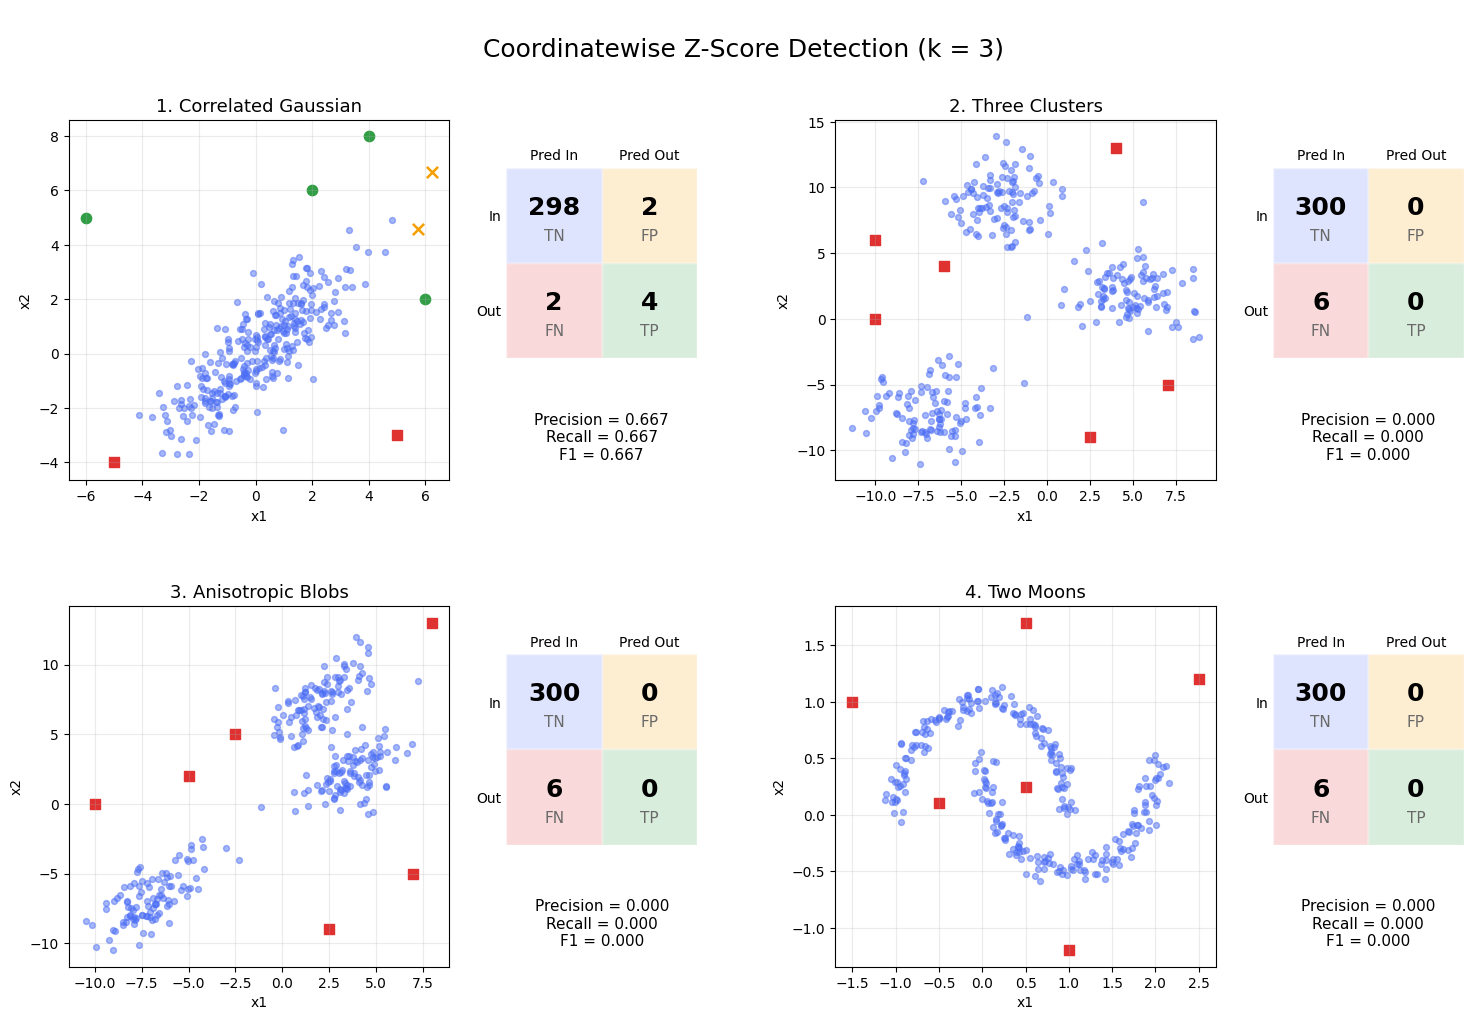

In [13]:
k = 3

y_pred_list = []

for X, y_true, title in datasets:

    mu = X.mean(axis=0)
    sigma = X.std(axis=0)

    z = (X - mu) / sigma
    y_pred = np.any(np.abs(z) > k, axis=1)

    y_pred_list.append(y_pred)

plot_method_comparison(
    datasets,
    y_pred_list,
    method_title=f"\nCoordinatewise Z-Score Detection (k = {k})"
)

#### Method 2: Mahalanobis Distance

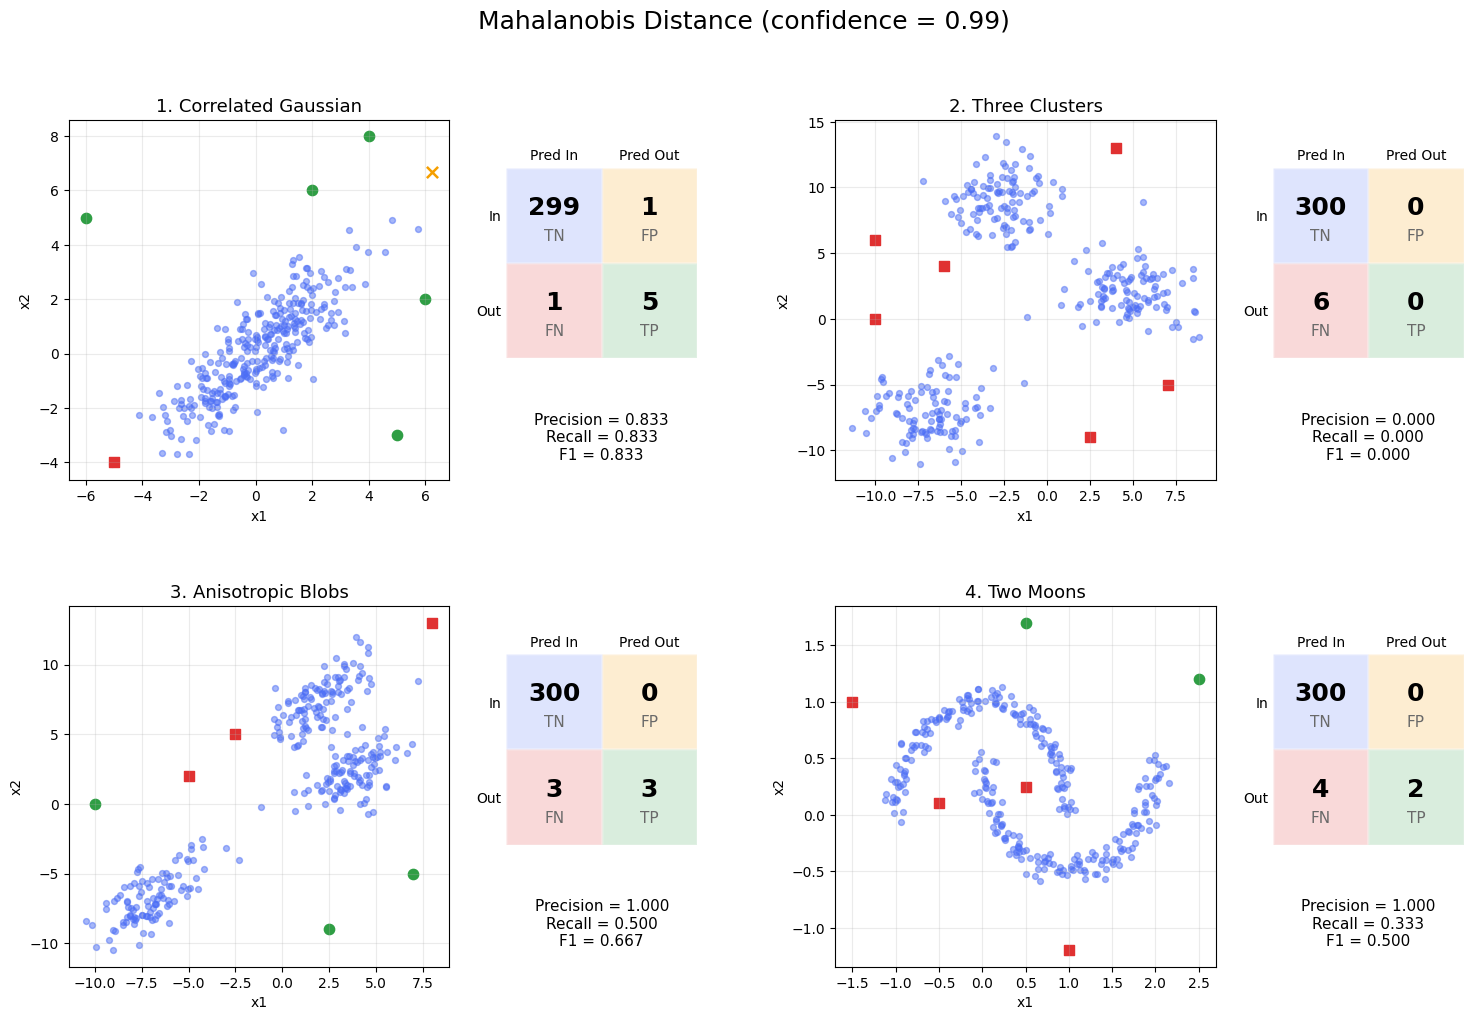

In [14]:
from scipy.stats import chi2

confidence = 0.99

y_pred_list = []

for X, y_true, title in datasets:

    mu = X.mean(axis=0)
    cov = np.cov(X, rowvar=False)

    diff = X - mu

    # Squared Mahalanobis distance
    d2 = np.sum((diff @ np.linalg.inv(cov)) * diff, axis=1)

    # Chi-square decision threshold
    threshold = chi2.ppf(confidence, df=X.shape[1])

    y_pred = d2 > threshold

    y_pred_list.append(y_pred)

plot_method_comparison(
    datasets,
    y_pred_list,
    method_title=f"Mahalanobis Distance (confidence = {confidence})"
)

#### Method 3A: DBSCAN — Fixed Neighborhood Radius (eps)

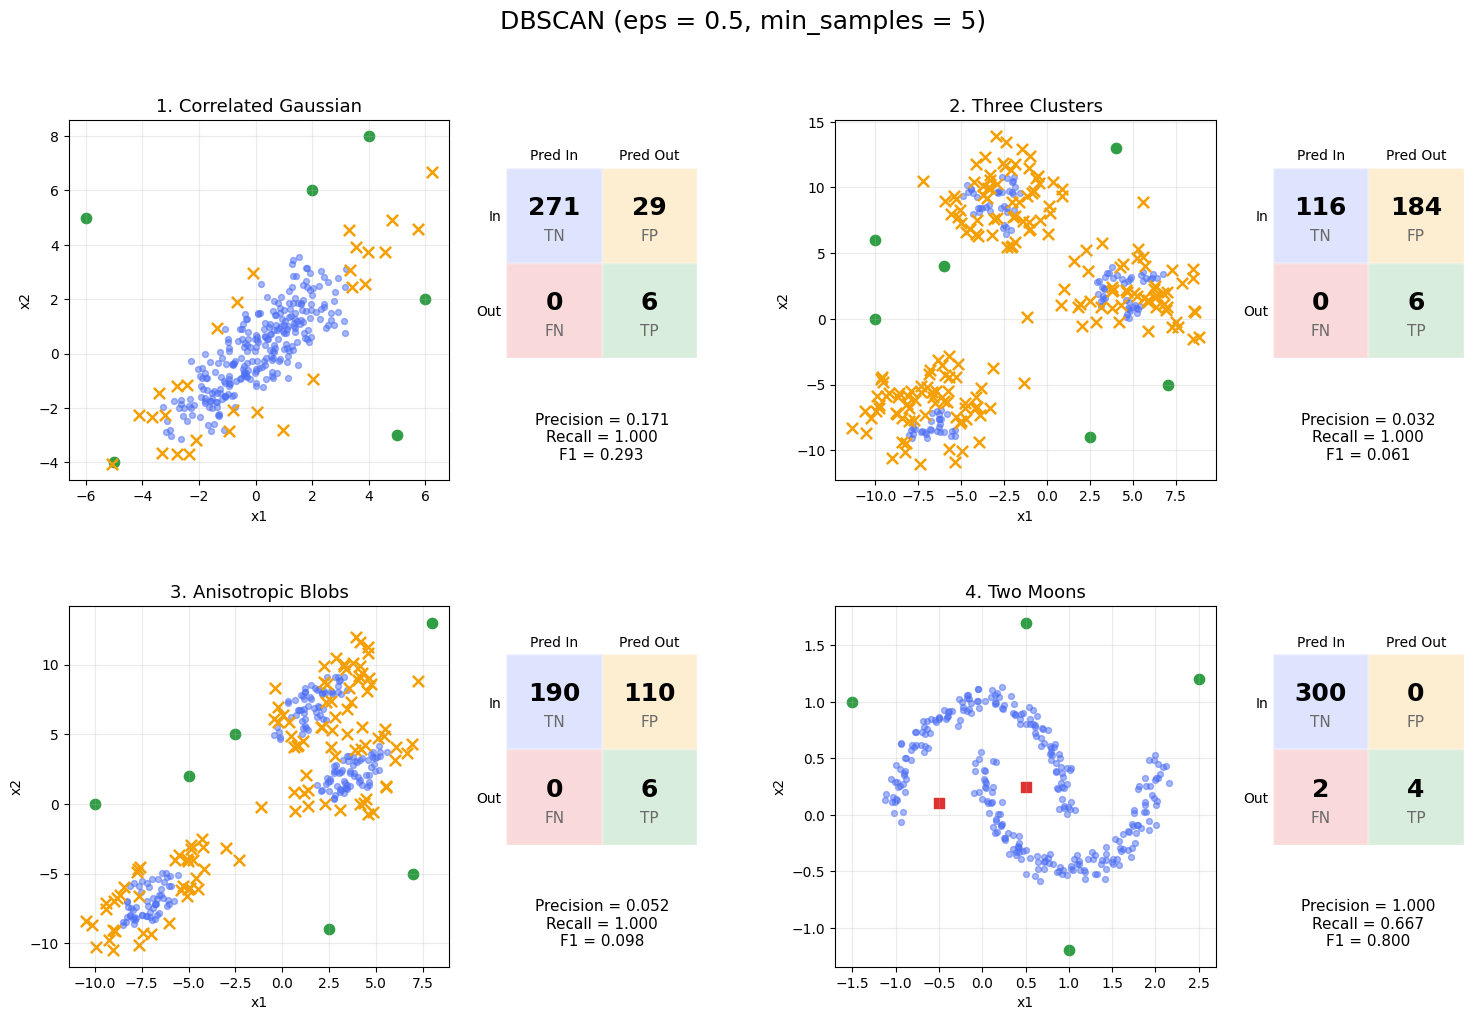

In [15]:
from sklearn.cluster import DBSCAN

eps = 0.5
min_samples = 5

y_pred_list = []

for X, y_true, title in datasets:

    # Fit DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(X)

    # DBSCAN labels noise points as -1
    y_pred = labels == -1

    y_pred_list.append(y_pred)

plot_method_comparison(
    datasets,
    y_pred_list,
    method_title=f"DBSCAN (eps = {eps}, min_samples = {min_samples})"
)

#### Method 3B: DBSCAN with EPS values tuned to each set

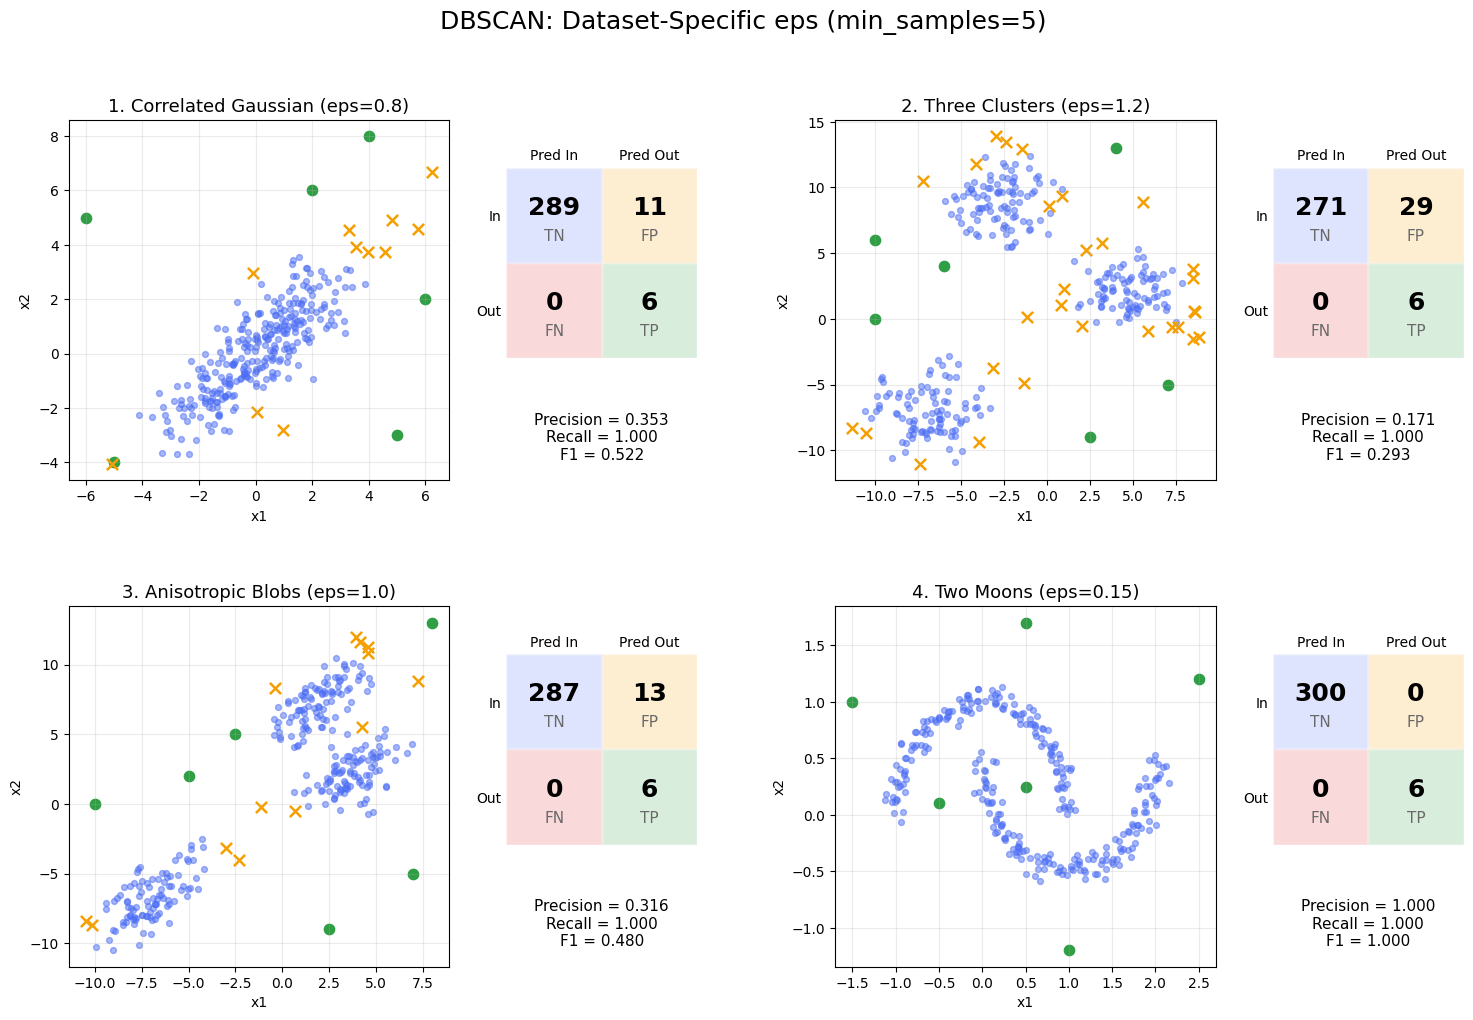

In [16]:
eps_values = [0.8, 1.2, 1.0, 0.15]
min_samples = 5

y_pred_list = []

for (X, y_true, title), eps in zip(datasets, eps_values):

    dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = dbscan.fit_predict(X)
    y_pred = labels == -1

    y_pred_list.append(y_pred)

# Include the selected eps value in each dataset title
datasets_labeled = [
    (X, y_true, f"{title} (eps={eps})")
    for (X, y_true, title), eps in zip(datasets, eps_values)
]

plot_method_comparison(
    datasets_labeled,
    y_pred_list,
    method_title=f"DBSCAN: Dataset-Specific eps (min_samples={min_samples})"
)

#### Method 4: Local Outlier Factor (LOF)

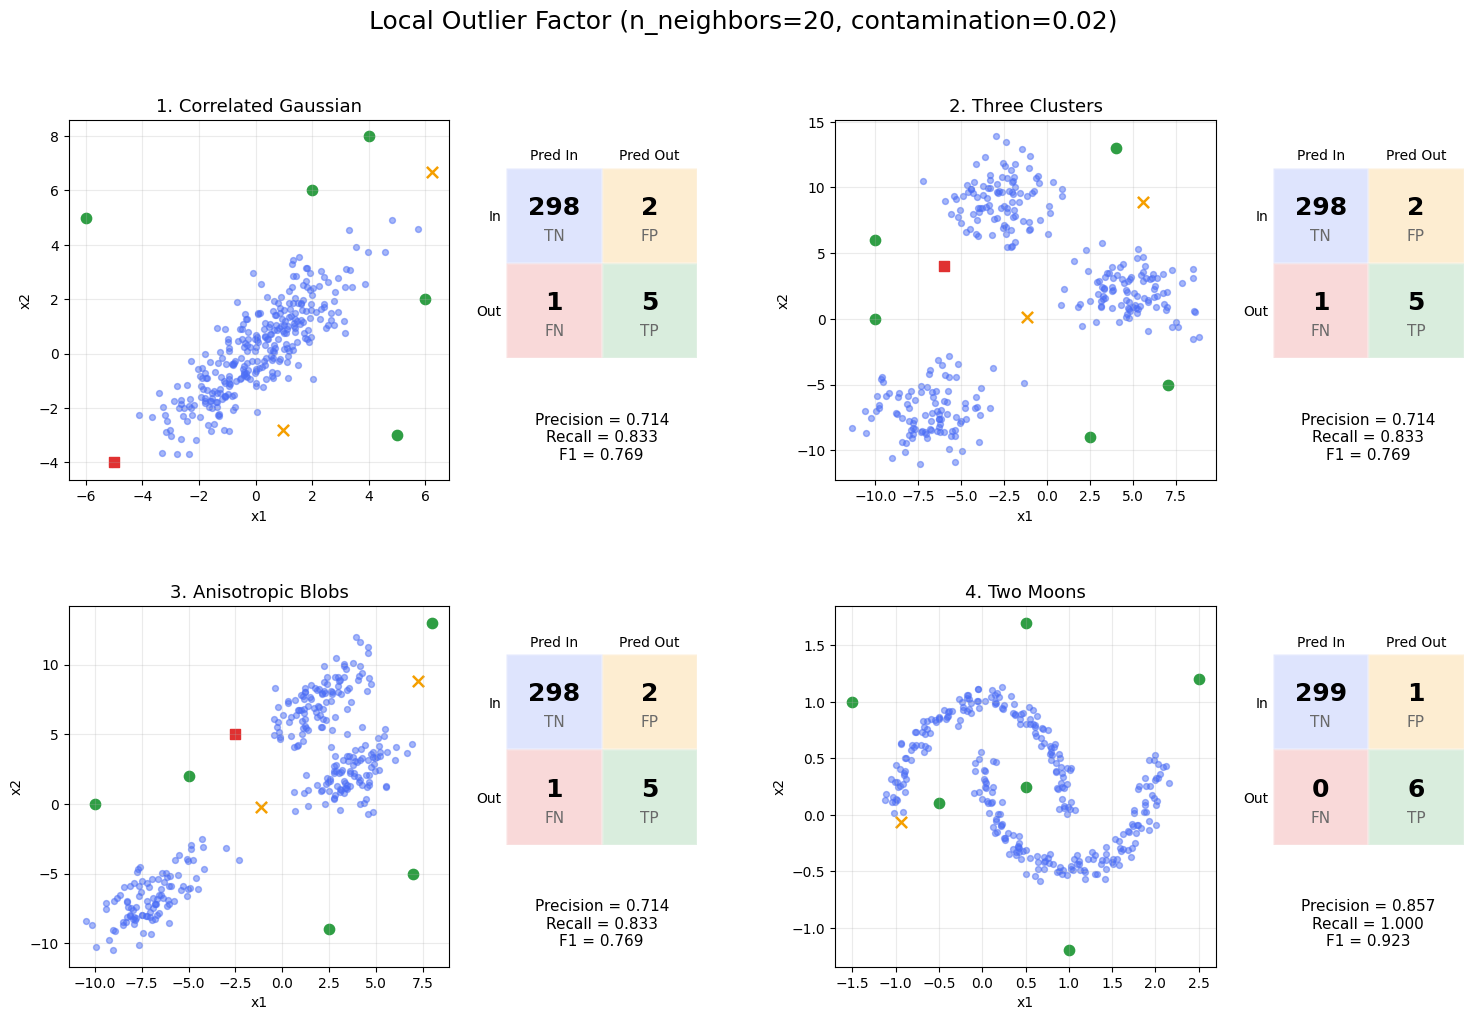

In [17]:
from sklearn.neighbors import LocalOutlierFactor

n_neighbors = 20
contamination = 0.02

y_pred_list = []

for X, y_true, title in datasets:

    # Fit Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    labels = lof.fit_predict(X)

    # LOF labels outliers as -1
    y_pred = labels == -1

    y_pred_list.append(y_pred)

plot_method_comparison(
    datasets,
    y_pred_list,
    method_title=(
        f"Local Outlier Factor "
        f"(n_neighbors={n_neighbors}, contamination={contamination})"
    )
)

#### Method 5: Isolation Forest

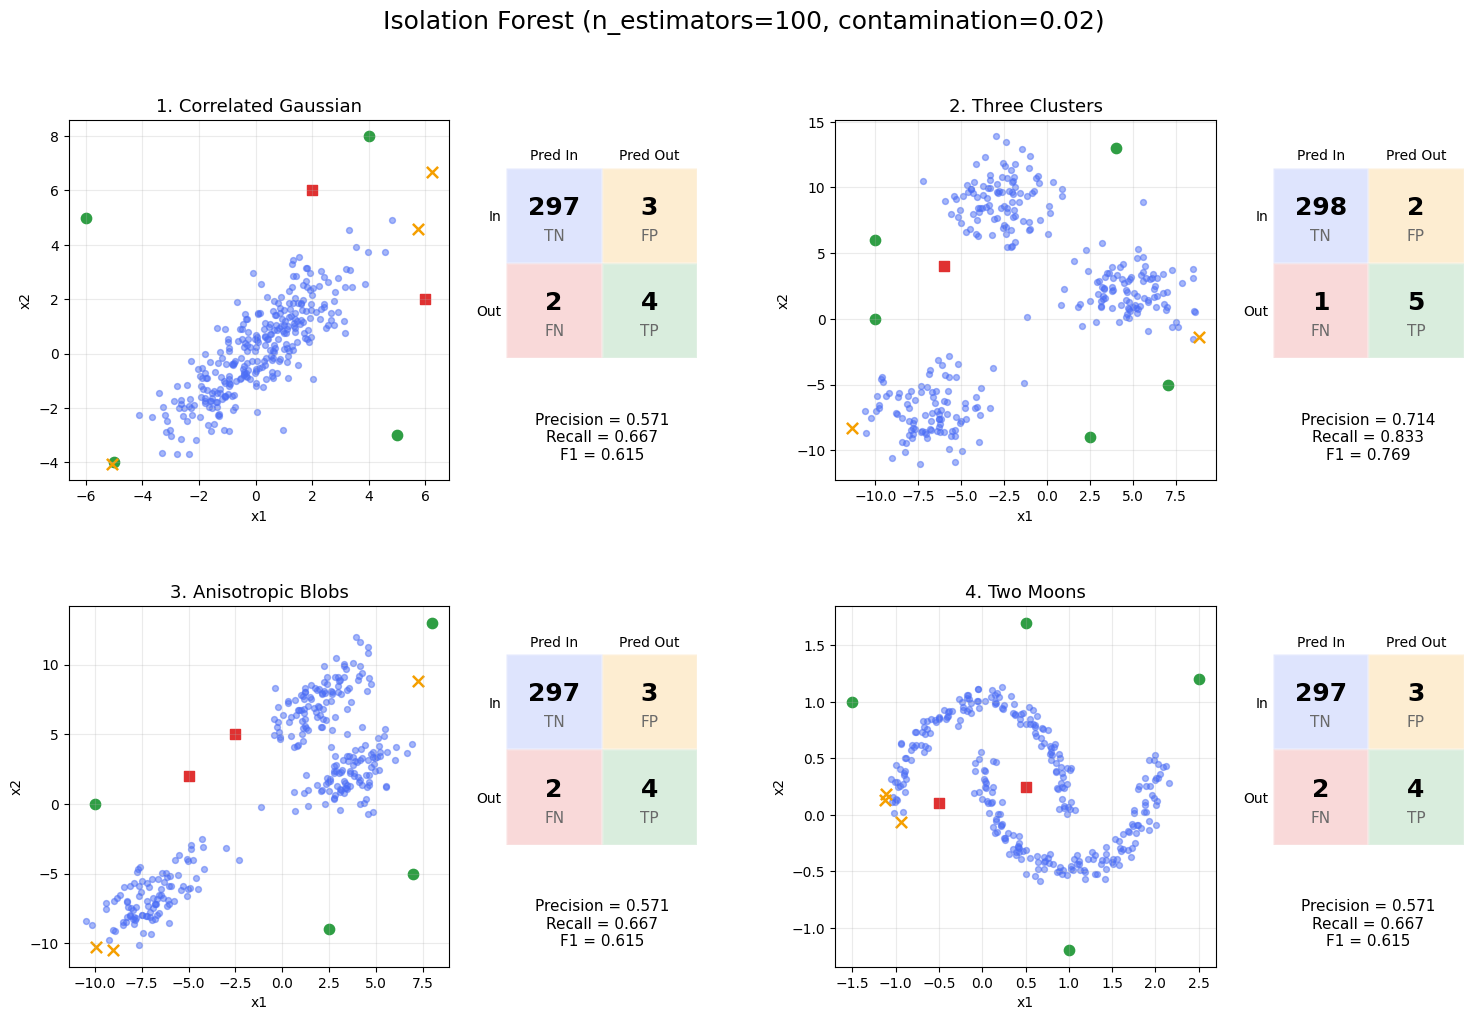

In [18]:
from sklearn.ensemble import IsolationForest

n_estimators = 100
contamination = 0.02

y_pred_list = []

for X, y_true, title in datasets:

    # Fit Isolation Forest
    iso = IsolationForest(
        n_estimators=n_estimators,
        contamination=contamination,
        random_state=random_seed
    )

    labels = iso.fit_predict(X)

    # Isolation Forest labels outliers as -1
    y_pred = labels == -1

    y_pred_list.append(y_pred)

plot_method_comparison(
    datasets,
    y_pred_list,
    method_title=(
        f"Isolation Forest "
        f"(n_estimators={n_estimators}, contamination={contamination})"
    )
)

### Summary

In [19]:
# Same settings as the individual experiments
eps_values = [0.8, 1.2, 1.0, 0.15]
min_samples = 5
contamination = 0.02

results = []

for (X, y_true, title), eps in zip(datasets, eps_values):

    # 1. Coordinatewise Z-score
    z = (X - X.mean(axis=0)) / X.std(axis=0)
    pred_z = np.any(np.abs(z) > 3, axis=1)

    # 2. Mahalanobis distance
    mu = X.mean(axis=0)
    diff = X - mu
    cov = np.cov(X, rowvar=False)
    d2 = np.sum((diff @ np.linalg.inv(cov)) * diff, axis=1)
    pred_mahal = d2 > chi2.ppf(0.99, df=X.shape[1])

    # 3. DBSCAN
    pred_dbscan = DBSCAN(
        eps=eps, min_samples=min_samples
    ).fit_predict(X) == -1

    # 4. Local Outlier Factor
    pred_lof = LocalOutlierFactor(
        n_neighbors=20, contamination=contamination
    ).fit_predict(X) == -1

    # 5. Isolation Forest
    pred_iso = IsolationForest(
        n_estimators=100,
        contamination=contamination,
        random_state=random_seed
    ).fit_predict(X) == -1

    predictions = {
        "Coordinatewise Z-Score": pred_z,
        "Mahalanobis": pred_mahal,
        "DBSCAN": pred_dbscan,
        "LOF": pred_lof,
        "Isolation Forest": pred_iso
    }

    # Compute confusion matrix counts and classification metrics
    for method, y_pred in predictions.items():

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[False, True]
        ).ravel()

        results.append({
            "Dataset": title,
            "Method": method,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)
        })

# Create one comparison table per dataset
results_df = pd.DataFrame(results)

for title in results_df["Dataset"].unique():

    print(f"\n{title}")

    table = results_df.loc[
        results_df["Dataset"] == title,
        ["Method", "TN", "FP", "FN", "TP", "Precision", "Recall", "F1"]
    ].set_index("Method")

    display(table.round(3))


1. Correlated Gaussian


,TN,FP,FN,TP,Precision,Recall,F1
Method,,,,,,,
Coordinatewise Z-Score,298,2,2,4,0.667,0.667,0.667
Mahalanobis,299,1,1,5,0.833,0.833,0.833
DBSCAN,289,11,0,6,0.353,1.000,0.522
LOF,298,2,1,5,0.714,0.833,0.769
Isolation Forest,297,3,2,4,0.571,0.667,0.615



2. Three Clusters


,TN,FP,FN,TP,Precision,Recall,F1
Method,,,,,,,
Coordinatewise Z-Score,300,0,6,0,0.000,0.000,0.000
Mahalanobis,300,0,6,0,0.000,0.000,0.000
DBSCAN,271,29,0,6,0.171,1.000,0.293
LOF,298,2,1,5,0.714,0.833,0.769
Isolation Forest,298,2,1,5,0.714,0.833,0.769



3. Anisotropic Blobs


,TN,FP,FN,TP,Precision,Recall,F1
Method,,,,,,,
Coordinatewise Z-Score,300,0,6,0,0.000,0.000,0.000
Mahalanobis,300,0,3,3,1.000,0.500,0.667
DBSCAN,287,13,0,6,0.316,1.000,0.480
LOF,298,2,1,5,0.714,0.833,0.769
Isolation Forest,297,3,2,4,0.571,0.667,0.615



4. Two Moons


,TN,FP,FN,TP,Precision,Recall,F1
Method,,,,,,,
Coordinatewise Z-Score,300,0,6,0,0.000,0.000,0.000
Mahalanobis,300,0,4,2,1.000,0.333,0.500
DBSCAN,300,0,0,6,1.000,1.000,1.000
LOF,299,1,0,6,0.857,1.000,0.923
Isolation Forest,297,3,2,4,0.571,0.667,0.615


### Discussion: Comparing the Methods

Our experiments demonstrate that **there is no universally best outlier detection method**. Performance depends on the structure of the data and on how each algorithm defines an outlier.

- **Coordinatewise Z-scores** identify extreme feature values but may miss unusual combinations of otherwise ordinary values.
- **Mahalanobis distance** performs particularly well for approximately elliptical distributions, where accounting for correlations is important.
- **DBSCAN** can detect outliers around irregularly shaped clusters, but its performance is sensitive to the neighborhood radius `eps`. In our experiments, it detected every planted outlier, sometimes at the cost of many false positives.
- **Local Outlier Factor (LOF)** performed consistently well across all four datasets by comparing each observation's density with that of its neighbors.
- **Isolation Forest** produced reasonable results without explicitly modeling distances, densities, or covariance, but was not the best method for these datasets.

**An important qualification:** We can calculate confusion matrices, precision, recall, and F1 because we deliberately introduced outliers and know their true labels. In real-world unsupervised outlier detection, these labels may not be available.

Finally, **detecting an outlier does not necessarily mean it should be removed**. Outliers may represent errors, legitimate rare observations, or precisely the events we are interested in identifying.

## Another Approach: Detecting Outliers Using Model Errors

We have examined methods that identify unusual observations based on feature values, distances, densities, and isolation.

Another approach is to use a **predictive model**, such as a regression tree or neural network. If a model predicts most observations accurately but makes a particularly large error on one observation, that observation may be anomalous.

For regression, we can use the absolute residual as an anomaly score:

$$
s_i = |y_i-\hat{y}_i|
$$

Large residuals may indicate incorrect data, unusual observations, or patterns that the model has not learned. Ideally, these errors should be calculated using **out-of-sample predictions**, since a sufficiently complex model may memorize its training observations, including outliers.

This approach requires a target variable, unlike the unsupervised methods we have studied.

**Our next technique, autoencoders, uses a related idea:** instead of predicting a separate target variable, a neural network attempts to reconstruct its input. Observations with unusually large reconstruction errors are considered potential anomalies.

## Autoencoder-Based Outlier Detection

Our previous methods identified outliers using statistical distances, local density, or random partitions of feature space.

We will now explore a neural network approach using an **autoencoder**.

An autoencoder is a neural network trained to reproduce its input. It typically consists of two components:

- **Encoder:** Compresses the input into a smaller representation.
- **Decoder:** Attempts to reconstruct the original input from that representation.

The network is trained to minimize **reconstruction error**, the difference between the original input and its reconstruction.

For outlier detection, we train an autoencoder using only observations considered normal. The idea is that the network will learn to reconstruct these observations well, but may have greater difficulty reconstructing unfamiliar observations.

### Our Experiment: Learning Handwritten 5s

We will use the MNIST handwritten digit dataset, treating **5 as the normal class** and all other digits as potential anomalies.

Our autoencoder will be trained exclusively on images of handwritten 5s. We will then evaluate it on images of all ten digits.

This raises an interesting question: **Will the autoencoder reconstruct all handwritten 5s better than other digits, or will some unusual 5s be harder to reconstruct than certain non-5s?**

Unlike a classification network, our autoencoder will not be trained to predict digit labels. It will learn only to reconstruct the images it sees during training.

In [20]:
# Utility to plot autoencoder learning curves (MSE)

def plot_learning_curves(hist,
                         title="Autoencoder Learning Curves",
                         best_epoch=None,      # None = epoch with minimum val_loss
                                               # Otherwise, 0-based epoch index
                         verbose=True
                        ):

    train_losses = hist.history["loss"]
    val_losses = hist.history["val_loss"]

    if best_epoch is not None:
        min_val_epoch = best_epoch
    else:
        min_val_epoch = int(np.argmin(val_losses))

    val_loss_at_min = val_losses[min_val_epoch]

    n_epochs = len(val_losses)
    epochs = list(range(1, n_epochs + 1))

    # Determine tick interval and xticks starting from 0
    tick_interval = max(1, n_epochs // 20)
    xticks = list(range(0, n_epochs + 1, tick_interval))

    plt.figure(figsize=(8, 5))

    plt.plot(epochs, train_losses, label="Training MSE")
    plt.plot(epochs, val_losses, label="Validation MSE")

    plt.scatter(
        min_val_epoch + 1,
        val_loss_at_min,
        color="red",
        marker="x",
        s=60,
        label="Min Validation MSE" if best_epoch is None else "Selected Epoch"
    )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.xticks(xticks)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training MSE:       {train_losses[-1]:.5f}")
        print(f"Final Validation MSE:     {val_losses[-1]:.5f}")
        print(f"Minimum Validation MSE:   {min(val_losses):.5f} "
              f"(Epoch {np.argmin(val_losses) + 1})")

        if best_epoch is not None:
            print(f"Selected Validation MSE:  {val_loss_at_min:.5f} "
                  f"(Epoch {min_val_epoch + 1})")

In [21]:
keras.utils.set_random_seed(random_seed)

# Load MNIST
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel intensities to [0, 1]
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

normal_digit = 5

# Train and validate exclusively on 5s
X_fives = X_train_full[y_train_full == normal_digit]

X_train, X_val = train_test_split(
    X_fives,
    test_size=0.2,
    random_state=random_seed
)

print(f"Training 5s:   {len(X_train):,}")
print(f"Validation 5s: {len(X_val):,}")
print(f"Test images:   {len(X_test):,}")

Training 5s:   4,336
Validation 5s: 1,085
Test images:   10,000


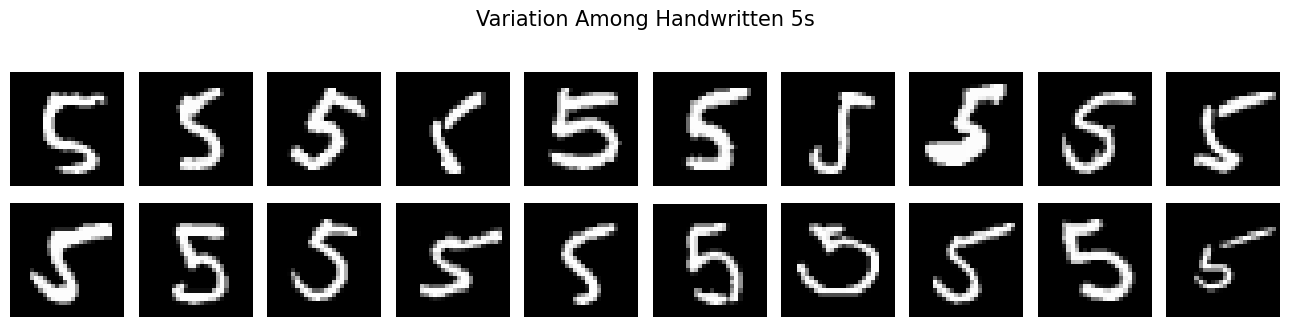

In [22]:
rng = np.random.default_rng(random_seed)

indices = rng.choice(len(X_train), size=20, replace=False)

fig, axes = plt.subplots(2, 10, figsize=(13, 3.5))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_train[idx], cmap="gray")
    ax.axis("off")

fig.suptitle("Variation Among Handwritten 5s", fontsize=15)
plt.tight_layout()
plt.show()

### Building and Training the Autoencoder

We will construct a simple **Dense autoencoder** with a symmetrical architecture:

**784 → 128 → 32 → 128 → 784**

Each 28 × 28 image is flattened into a vector of 784 pixel values.

- The **encoder** compresses the image into a representation containing just 32 values.
- The **decoder** attempts to reconstruct the original image from this compressed representation.
- The output layer uses **sigmoid activation** because our pixel intensities are between 0 and 1.

We will train the network to minimize **mean squared reconstruction error**:

$$\
E(x,\hat{x})=\frac{1}{784}\sum\_{j=1}^{784}(x_j-\hat{x}\_j)^2.\
$$

Notice that the input image is also the training target: the network learns to reproduce its input rather than predict a digit label.

Because we train exclusively on handwritten 5s, we hope the network will reconstruct ordinary 5s more accurately than other digits. However, this is a hypothesis we will test, not a guarantee.

In [23]:

# Flatten images into vectors of 784 pixels
X_train_flat = X_train.reshape(-1, 784)
X_val_flat = X_val.reshape(-1, 784)

autoencoder = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(32, activation="relu"),   # Bottleneck
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="sigmoid")
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

history = autoencoder.fit(
    X_train_flat,
    X_train_flat,
    validation_data=(X_val_flat, X_val_flat),
    epochs=50,
    batch_size=128,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

2026-10-11 21:29:07.783284: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2026-10-11 21:29:07.783307: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 64.00 GB
2026-10-11 21:29:07.783311: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 24.00 GB
I0000 00:00:1791768547.783333 24185978 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791768547.783380 24185978 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


2026-10-11 21:29:08.046165: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1037 - val_loss: 0.0566
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0508 - val_loss: 0.0457
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0427 - val_loss: 0.0401
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0378 - val_loss: 0.0356
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0338 - val_loss: 0.0324
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0309 - val_loss: 0.0299
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0283 - val_loss: 0.0276
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0261 - val_loss: 0.0256
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0242 - val_loss: 0.0240
Epoch 10/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0226 - val_loss: 0.0227
Epoch 11/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0214 - val_loss: 0.0217
Epoch 12/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0205 - val_loss: 0.0209


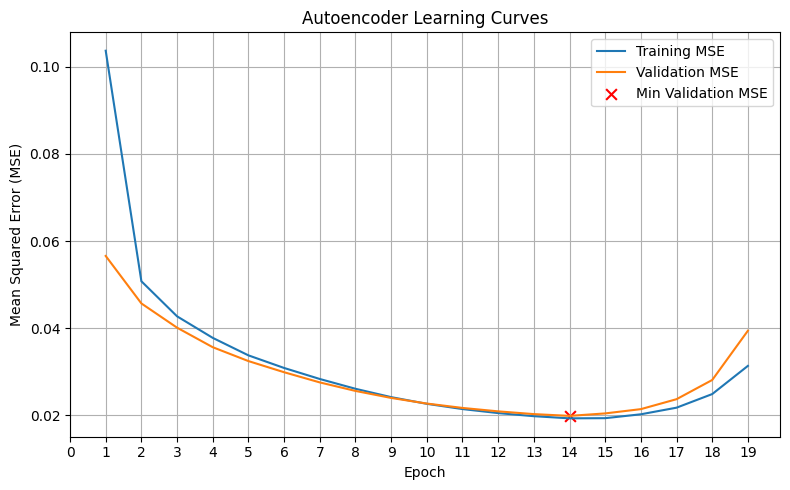

Final Training MSE:       0.03134
Final Validation MSE:     0.03941
Minimum Validation MSE:   0.01987 (Epoch 14)


In [24]:
plot_learning_curves(history)

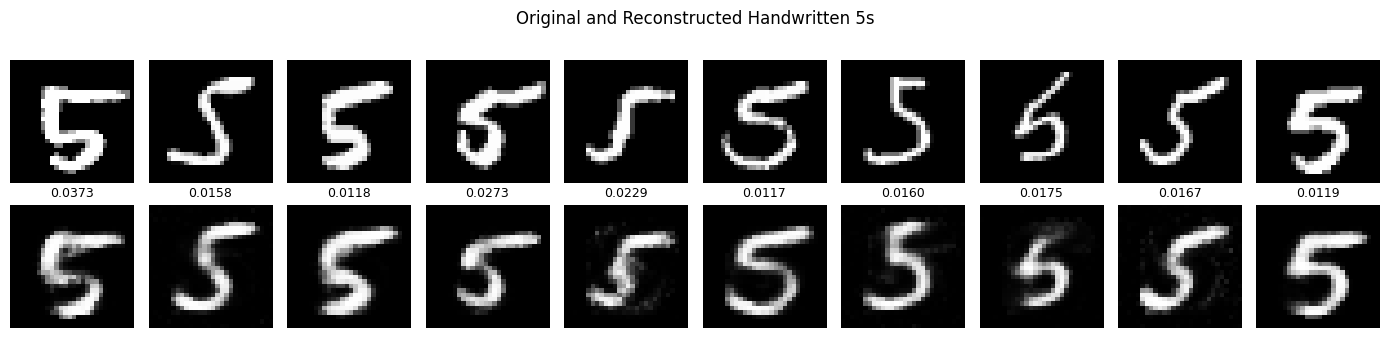

In [25]:
rng = np.random.default_rng(random_seed)
indices = rng.choice(len(X_val), size=10, replace=False)

originals = X_val_flat[indices]
reconstructions = autoencoder.predict(originals, verbose=0)

errors = np.mean((originals - reconstructions)**2, axis=1)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))

for i in range(10):
    axes[0, i].imshow(originals[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")

    axes[0, i].axis("off")
    axes[1, i].axis("off")
    axes[1, i].set_title(f"{errors[i]:.4f}", fontsize=9)

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")

plt.suptitle("Original and Reconstructed Handwritten 5s")
plt.tight_layout()
plt.show()

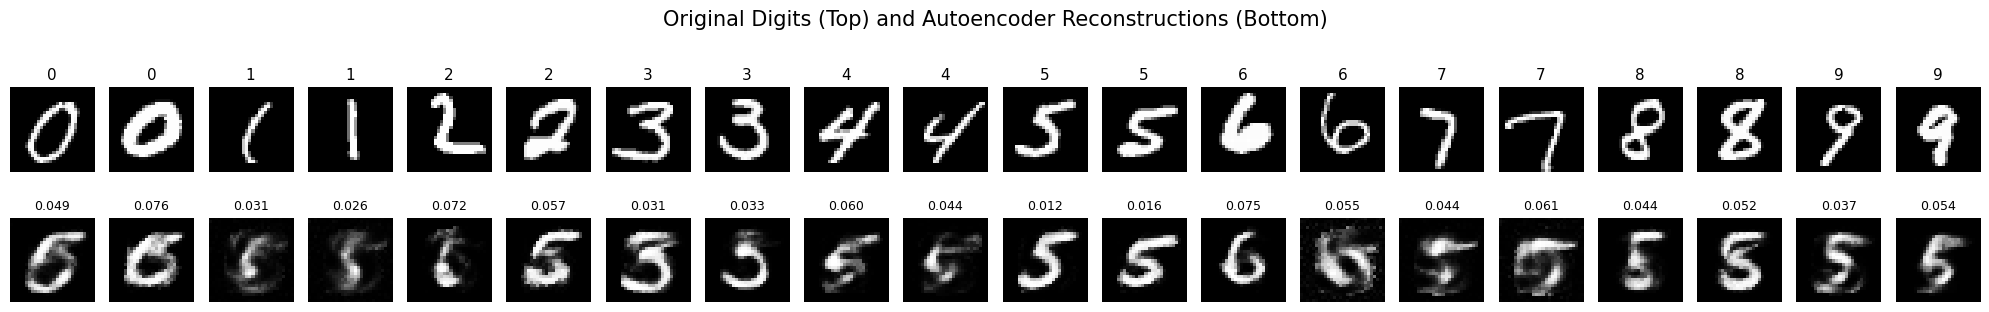

In [26]:
# Two test examples of each digit, 0–9
rng = np.random.default_rng(random_seed)

indices = np.concatenate([
    rng.choice(np.flatnonzero(y_test == digit), size=2, replace=False)
    for digit in range(10)
])

originals = X_test[indices].reshape(-1, 784)
reconstructions = autoencoder.predict(originals, verbose=0)
errors = np.mean((originals - reconstructions)**2, axis=1)

fig, axes = plt.subplots(2, 20, figsize=(20, 3.5))

for i, idx in enumerate(indices):
    axes[0, i].imshow(originals[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(reconstructions[i].reshape(28, 28), cmap="gray")

    axes[0, i].set_title(f"{y_test[idx]}", fontsize=11)
    axes[1, i].set_title(f"{errors[i]:.3f}", fontsize=9)

    axes[0, i].axis("off")
    axes[1, i].axis("off")

fig.suptitle(
    "Original Digits (Top) and Autoencoder Reconstructions (Bottom)",
    fontsize=15
)

plt.tight_layout()
plt.show()

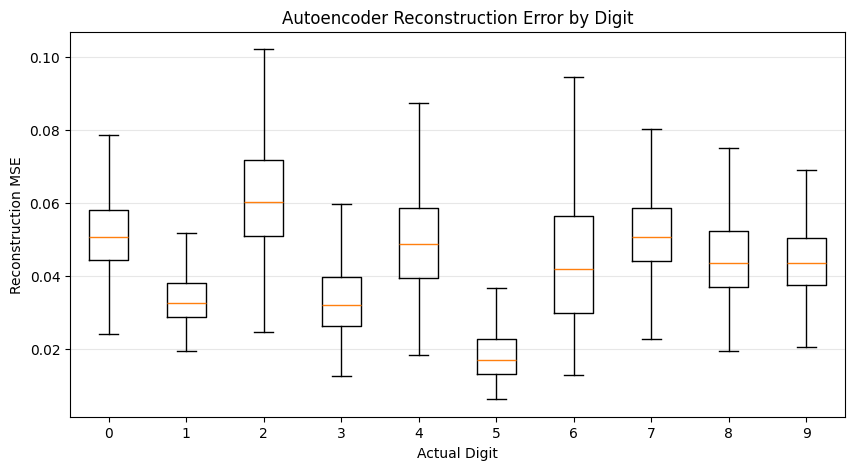

In [27]:
# Reconstruct all MNIST test images
X_test_flat = X_test.reshape(-1, 784)

X_reconstructed = autoencoder.predict(
    X_test_flat, batch_size=256, verbose=0
)

# MSE for each image
test_errors = np.mean(
    (X_test_flat - X_reconstructed)**2,
    axis=1
)

# Compare reconstruction errors by digit
errors_by_digit = [
    test_errors[y_test == digit]
    for digit in range(10)
]

plt.figure(figsize=(10, 5))

plt.boxplot(
    errors_by_digit,
    tick_labels=[str(d) for d in range(10)],
    showfliers=False
)

plt.xlabel("Actual Digit")
plt.ylabel("Reconstruction MSE")
plt.title("Autoencoder Reconstruction Error by Digit")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Detecting Anomalies Using Reconstruction Error

Our autoencoder generally reconstructs handwritten 5s more accurately than other digits. However, the reconstruction-error distributions overlap, so we cannot perfectly distinguish normal observations from anomalies.

To turn reconstruction error into an anomaly detector, we must choose a threshold $T$:

$$
\text{Predict anomaly if } E(x)>T.
$$

We will set $T$ to the **95th percentile of reconstruction errors on the validation 5s**. This threshold is selected using only normal observations, without examining the labels or errors of anomalous test images.

Under this rule, approximately 5% of the validation 5s will be classified as anomalies, even though they are genuine 5s.

We can then evaluate the detector on unseen test images, where we know the true digit labels, and calculate precision, recall, F1, and a confusion matrix.

This illustrates a general principle: **anomaly detection involves both choosing a measure of unusualness and deciding how unusual an observation must be before we flag it.**

Threshold (95th percentile): 0.03592


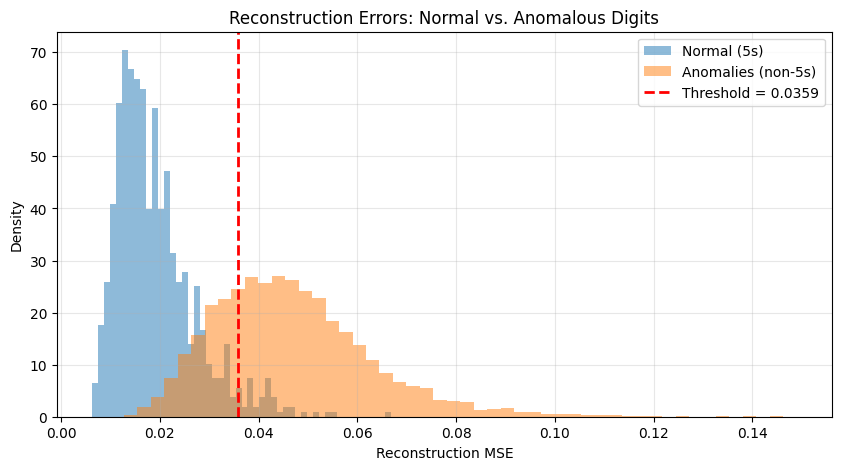

In [28]:
# Reconstruction errors on validation 5s
val_reconstructed = autoencoder.predict(
    X_val_flat, batch_size=256, verbose=0
)

val_errors = np.mean(
    (X_val_flat - val_reconstructed)**2,
    axis=1
)

# Flag observations above the 95th percentile
percentile = 95
threshold = np.percentile(val_errors, percentile)

print(f"Threshold ({percentile}th percentile): {threshold:.5f}")

# Visualize threshold relative to test reconstruction errors
plt.figure(figsize=(10, 5))

plt.hist(
    test_errors[y_test == 5],
    bins=50,
    density=True,
    alpha=0.5,
    label="Normal (5s)"
)

plt.hist(
    test_errors[y_test != 5],
    bins=50,
    density=True,
    alpha=0.5,
    label="Anomalies (non-5s)"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {threshold:.4f}"
)

plt.xlabel("Reconstruction MSE")
plt.ylabel("Density")
plt.title("Reconstruction Errors: Normal vs. Anomalous Digits")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score
)

rng = np.random.default_rng(random_seed)

# Select all test 5s and approximately 10% anomalies
normal_indices = np.flatnonzero(y_test == 5)
anomaly_indices = rng.choice(
    np.flatnonzero(y_test != 5),
    size=round(len(normal_indices) / 9),
    replace=False
)

test_indices = np.concatenate([normal_indices, anomaly_indices])
rng.shuffle(test_indices)

# Ground truth: True means anomaly
y_true = y_test[test_indices] != 5

# Predictions from previously calculated reconstruction errors
y_pred = test_errors[test_indices] > threshold

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[False, True]
).ravel()

print(f"Test observations: {len(test_indices)}")
print(f"Normal (5s):       {(~y_true).sum()}")
print(f"Anomalies:         {y_true.sum()}\n")

print(f"TN = {tn}, FP = {fp}")
print(f"FN = {fn}, TP = {tp}\n")

print(f"Precision: {precision_score(y_true, y_pred):.3f}")
print(f"Recall:    {recall_score(y_true, y_pred):.3f}")
print(f"F1:        {f1_score(y_true, y_pred):.3f}")

Test observations: 991
Normal (5s):       892
Anomalies:         99

TN = 851, FP = 41
FN = 22, TP = 77

Precision: 0.653
Recall:    0.778
F1:        0.710


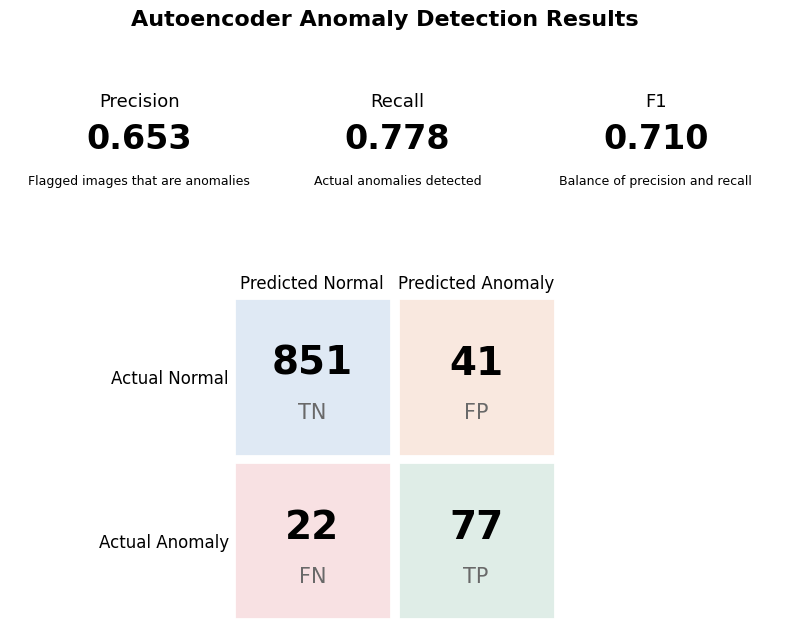

Test observations: 991
Normal observations: 892
Anomalies: 99
TN = 851, FP = 41, FN = 22, TP = 77
Precision:           0.653
Recall:              0.778
F1:                  0.710
False-positive rate: 4.6%


In [30]:
# Compute metrics
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[False, True]
).ravel()

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
fpr = fp / (fp + tn) if (fp + tn) else 0

# Create figure
fig = plt.figure(figsize=(10, 7))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 2.5], hspace=0.35)

# Top: summary metrics
ax1 = fig.add_subplot(gs[0])
ax1.axis("off")

metrics = [
    ("Precision", precision, "Flagged images that are anomalies"),
    ("Recall", recall, "Actual anomalies detected"),
    ("F1", f1, "Balance of precision and recall")
]

for i, (name, value, description) in enumerate(metrics):
    x = (i + 0.5) / 3

    ax1.text(x, 0.85, name, ha="center", fontsize=13)
    ax1.text(x, 0.53, f"{value:.3f}",
             ha="center", fontsize=24, fontweight="bold")
    ax1.text(x, 0.25, description,
             ha="center", fontsize=9)

# Bottom: confusion matrix
ax2 = fig.add_subplot(gs[1])

cm = np.array([[tn, fp], [fn, tp]])

colors = [
    ["#dfe9f4", "#f9e8df"],
    ["#f8e1e3", "#dfede7"]
]

for row in range(2):
    for col in range(2):
        ax2.add_patch(
            plt.Rectangle(
                (col, row), 0.96, 0.96,
                facecolor=colors[row][col],
                edgecolor="white",
                linewidth=2
            )
        )

        ax2.text(
            col + 0.48, row + 0.40,
            str(cm[row, col]),
            ha="center", va="center",
            fontsize=28, fontweight="bold"
        )

        label = [["TN", "FP"], ["FN", "TP"]][row][col]

        ax2.text(
            col + 0.48, row + 0.70,
            label,
            ha="center", va="center",
            fontsize=15, color="dimgray"
        )

ax2.set_xlim(0, 2)
ax2.set_ylim(2, 0)
ax2.set_aspect("equal")

ax2.set_xticks([0.48, 1.48])
ax2.set_xticklabels(["Predicted Normal", "Predicted Anomaly"], fontsize=12)
ax2.xaxis.tick_top()

ax2.set_yticks([0.48, 1.48])
ax2.set_yticklabels(["Actual Normal", "Actual Anomaly"], fontsize=12)

ax2.tick_params(length=0)
for spine in ax2.spines.values():
    spine.set_visible(False)

fig.suptitle("Autoencoder Anomaly Detection Results",
             fontsize=16, fontweight="bold", y=0.99)

plt.show()

# Text summary
print(f"Test observations: {len(y_true):,}")
print(f"Normal observations: {(~y_true).sum():,}")
print(f"Anomalies: {y_true.sum():,}")
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Precision:           {precision:.3f}")
print(f"Recall:              {recall:.3f}")
print(f"F1:                  {f1:.3f}")
print(f"False-positive rate: {fpr:.1%}")

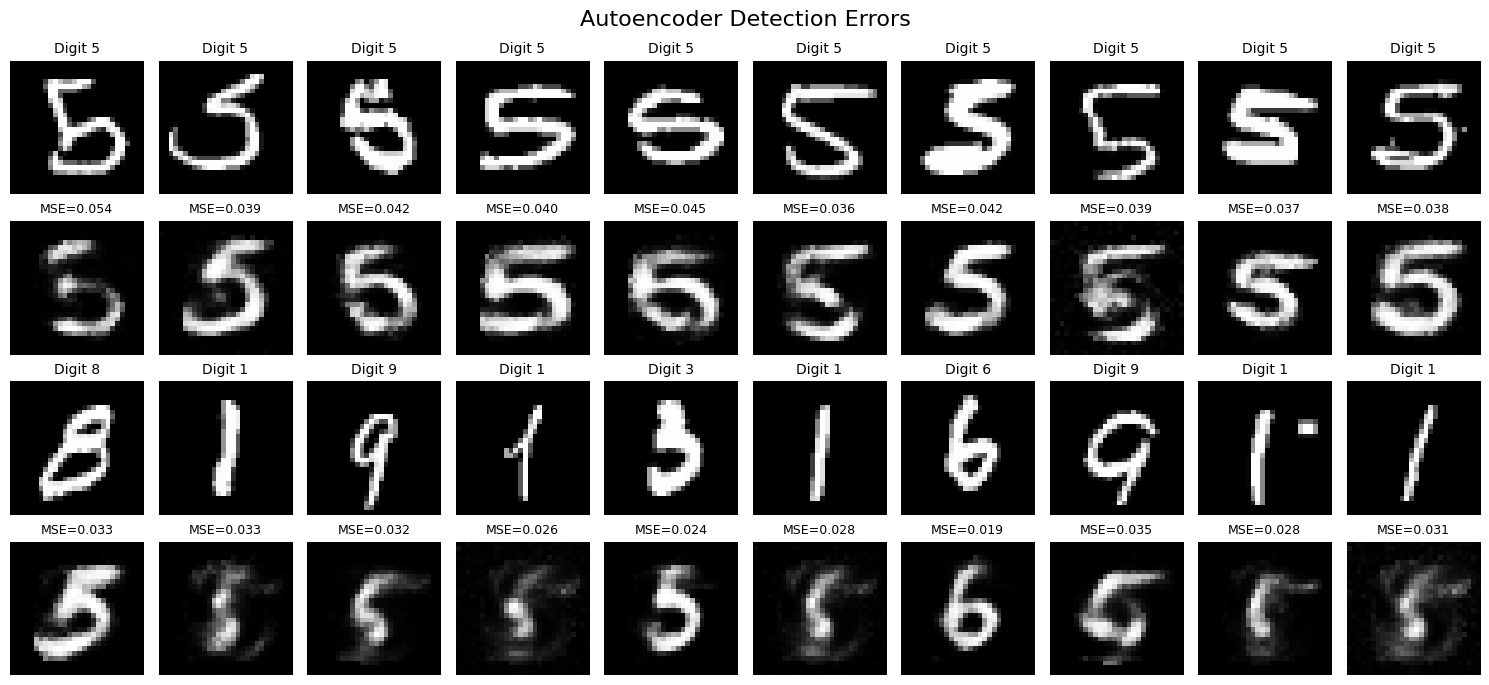

In [31]:
# Original test indices for the two types of errors


fp_indices = test_indices[(~y_true) & y_pred]
fn_indices = test_indices[y_true & (~y_pred)]

rng = np.random.default_rng(random_seed)

fig, axes = plt.subplots(4, 10, figsize=(15, 7))

for row, indices, label in [
    (0, fp_indices, "False Positives"),
    (2, fn_indices, "False Negatives")
]:
    selected = rng.choice(indices, size=min(10, len(indices)), replace=False)

    originals = X_test[selected].reshape(-1, 784)
    reconstructions = autoencoder.predict(originals, verbose=0)

    for i, idx in enumerate(selected):
        j = np.where(selected == idx)[0][0]

        axes[row, i].imshow(originals[j].reshape(28, 28), cmap="gray")
        axes[row + 1, i].imshow(reconstructions[j].reshape(28, 28), cmap="gray")

        axes[row, i].set_title(f"Digit {y_test[idx]}", fontsize=10)
        axes[row + 1, i].set_title(
            f"MSE={test_errors[idx]:.3f}", fontsize=9
        )

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("Autoencoder Detection Errors", fontsize=16)
plt.tight_layout()
plt.show()

### Discussion: Understanding Autoencoder Detection Errors

Our autoencoder achieved a precision of 0.653, recall of 0.778, and F1 score of 0.710 on a test set containing approximately 90% handwritten 5s and 10% other digits.

Examining the misclassified images reveals two important limitations:

- **False positives:** Some genuine handwritten 5s have unusual shapes or strokes that the autoencoder cannot reconstruct accurately. They are flagged as anomalies despite belonging to the normal class.
- **False negatives:** Some other digits, particularly handwritten 1s, have sufficiently low reconstruction errors to be classified as normal. Their relatively sparse images may contribute to their low pixel-level MSE.

Although the autoencoder was trained exclusively on handwritten 5s, it does not learn an explicit rule for recognizing the digit 5. It learns a compressed representation that helps reconstruct its training images.

Consequently, **reconstruction error is an imperfect measure of whether an observation is genuinely anomalous**.

This illustrates the central challenge of outlier detection: different methods define unusualness in different ways, and none can be expected to identify every anomaly without generating false alarms.

## Appendix: Understanding the Chi-Squared Decision Boundary

When we compute the squared Mahalanobis distance

$$
D_M(x)^2 = (x - \mu)^\top \Sigma^{-1} (x - \mu),
$$

we are measuring how far $x$ is from the mean $\mu$ **in units that match the actual geometry of the data**.
For a multivariate normal distribution, something remarkable happens:

> **The squared Mahalanobis distance follows a $\chi^2$ distribution with $p$ degrees of freedom.**

For our running 2D example, we have 2 degrees of freedom, so here is the shape of the distribution:

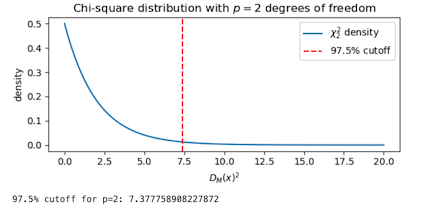

**Why $\chi^2$?**

If the data really were spherical and independent, then after whitening (removing correlations and scaling each feature to variance 1) we would have

$$
z = \Sigma^{-1/2}(x - \mu)
$$

and each component of $z$ would behave like a standard normal variable:

$$
z_1 \sim N(0,1),\quad
z_2 \sim N(0,1),\quad
\dots,\quad
z_p \sim N(0,1).
$$

Then

$$
D_M(x)^2 = z_1^2 + z_2^2 + \cdots + z_p^2.
$$

A sum of $p$ squared standard normal variables is exactly what defines a chi-square distribution with $p$ degrees of freedom.
So the chi-square distribution falls out naturally from the geometry.

**The $\chi^2$ decision boundary ellipse**

The decision boundary defined by your choice of $\chi^2$ parameter is a multivariate ellipse:

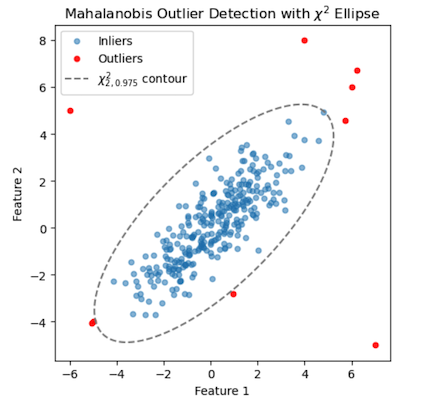

### What does the ellipse represent?

For $p=2$, the contour

$$
D_M(x)^2 = \chi^2_{2,\,0.975}
$$

consists of all points whose squared Mahalanobis distance equals the 97.5th percentile of the chi-square distribution with 2 degrees of freedom.

This contour forms an **ellipse rather than a circle** because the covariance matrix accounts for:

- **Different variances:** The data may be more spread out in one direction than another.
- **Correlations:** The data cloud may be tilted because the two features vary together.

Assuming a bivariate normal distribution, the ellipse encloses approximately **97.5% of the observations**:

- Points **inside** the ellipse have Mahalanobis distances consistent with this region of the distribution.
- Points **outside** the ellipse fall among the approximately 2.5% of observations with the largest Mahalanobis distances and may be considered outliers.

The geometric interpretation is particularly useful. Imagine transforming the data so that the features are uncorrelated and each has variance 1. This process is called **whitening**.

In this transformed space, the elliptical boundary becomes a circle, and Mahalanobis distance becomes ordinary Euclidean distance from the transformed mean.

Thus, **Mahalanobis distance measures how far an observation lies from the center while accounting for the shape, scale, and orientation of the data distribution**.

*Note:* The chi-square interpretation assumes multivariate normality and known population parameters. When the mean and covariance are estimated from the sample, the threshold is approximate.



